In [1]:
'''
detectability limits

can get the limit in flux and not in background - see what the dimmest actual star i trained on is
can look at how the efficiency of the NN looks depending on the brightness of the star
we can say that if the nn performs at baseline to all stars in the data, it would be x, otherwise it would be y.

make sure that the lightcurves are background subtracted when u do that

can put a scientific plot in

okay so then i get to say stuff about the upper limit


the other papers we’re looking at are looking at not associated with a star

can get number of star hours above a certain magnitude and the upper limit based on the detectability'''

'look at final cands again maybe??'

In [52]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib

plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [3]:
#step one: see what the flux of the dimmest star i trained on is
#okay so actually we need to extract light curves
save_dir = '/lustre/lrspec/ZTF_data/lightcurves/training/'

In [22]:
def load_xy_positions_from_info(info_path):
    info = np.load(info_path)
    xy_array = info[:,2:4]
    xy_array = np.unique(xy_array, axis=0)
    return xy_array

In [23]:
load_xy_positions_from_info('/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_streaks/info/ztf_20220820237546_000798_zr_c01_x_0004._2_stamps_info.npy')

array([[ 174,  715],
       [ 248, 2383],
       [ 264,  854],
       [1480,  506],
       [1503, 2697],
       [1546,  485],
       [1817, 2303],
       [2194, 1452],
       [2300, 2495],
       [2430, 1925]])

In [3]:
info_test = np.load('/lustre/lrspec/ZTF_data/training_feb26/offcenter_stamps_streaks/info/ztf_20220820237546_000798_zr_c01_x_0004._2_stamps_info.npy')

In [15]:
'ztf_20220820237546_000798_zr_c01_x_0004._2_stamps_info.npy'[:40]

'ztf_20220820237546_000798_zr_c01_x_0004.'

In [85]:
lc_filename = 'lightcurve_ztf_20220820237546_000798_zr_c01_x_0004_2_0174_0715.csv'

In [86]:
lc = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/1020/'+lc_filename)

FileNotFoundError: [Errno 2] No such file or directory: '/lustre/lrspec/ZTF_data/lightcurves/1020/lightcurve_ztf_20220820237546_000798_zr_c01_x_0004_2_0174_0715.csv'

In [4]:
info_test

array([[   0,    0,  174,  715,    0],
       [   0,    0,  174,  715,    1],
       [   0,    0,  174,  715,    2],
       [   0,    0,  174,  715,   -1],
       [   0,    0,  174,  715,   -2],
       [   0,    0,  248, 2383,    0],
       [   0,    0,  248, 2383,    1],
       [   0,    0,  248, 2383,    2],
       [   0,    0,  248, 2383,   -1],
       [   0,    0,  248, 2383,   -2],
       [   0,    0,  264,  854,    0],
       [   0,    0,  264,  854,    1],
       [   0,    0,  264,  854,    2],
       [   0,    0,  264,  854,   -1],
       [   0,    0,  264,  854,   -2],
       [   0,    0, 1480,  506,    0],
       [   0,    0, 1480,  506,    1],
       [   0,    0, 1480,  506,    2],
       [   0,    0, 1480,  506,   -1],
       [   0,    0, 1480,  506,   -2],
       [   0,    0, 1503, 2697,    0],
       [   0,    0, 1503, 2697,    1],
       [   0,    0, 1503, 2697,    2],
       [   0,    0, 1503, 2697,   -1],
       [   0,    0, 1503, 2697,   -2],
       [   0,    0, 1546,

Loading FITS file: /lustre/lrspec/ZTF_data/2022/1017/ztf_20221017148750_000831_zi_c03_x_0021.fits.fz
Processing 10 positions...
Calculating background...
Image shape: (3080, 3072)
Background value: 196.38
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0295_0812.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0306_1037.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0492_2968.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0783_0430.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0963_0802.csv
saving
/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_1532_2023.csv
saving
/lustre/lrspec/ZTF_data/li

KeyboardInterrupt: 

In [31]:
lc_test = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/training/lightcurve_ztf_20221017148750_000831_zi_c03_x_0021.fits.fz_4_0295_0812.csv')

In [32]:
lc_test

,position_id,x_input,y_input,row_index,flux_hap_2,flux_hap_3,flux_hap_4,flux_hap_5,max_col
0,0,295,812,0,750.074036,1262.256104,1794.390259,2376.326904,295.0
1,0,295,812,1,739.300659,1228.791016,1748.938477,2308.990234,295.0
2,0,295,812,2,731.924438,1240.279053,1783.002686,2379.033447,295.0
3,0,295,812,3,700.312134,1184.134521,1686.678467,2242.711914,295.0
4,0,295,812,4,733.076050,1269.718262,1828.783569,2448.924316,295.0
...,...,...,...,...,...,...,...,...,...
3075,0,295,812,3075,686.143677,1235.870361,1844.632202,2502.113037,294.0
3076,0,295,812,3076,687.905334,1221.744385,1823.190918,2477.567871,294.0
3077,0,295,812,3077,647.222717,1149.270142,1713.957520,2311.284424,294.0
3078,0,295,812,3078,666.627014,1188.294189,1770.345459,2389.471436,294.0


In [ ]:
#great so it works we have lcs now
#now we need to figure out:
#a) how low they go
#b) their correctly-predicted-ness as a function of flux

In [41]:
avg_fluxes = []
lc_folder = '/lustre/lrspec/ZTF_data/lightcurves/training/'
for file in os.listdir(lc_folder):
    lc = pd.read_csv(os.path.join(lc_folder, file))['flux_hap_2']
    avg_fluxes.append(np.average(lc))

In [46]:
np.min(avg_fluxes)

130.61321985319063

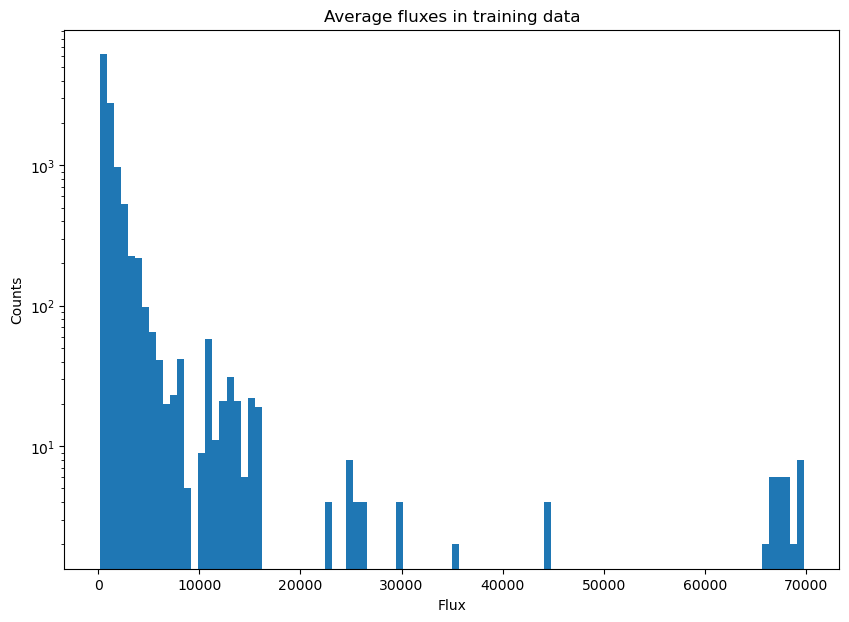

In [42]:
plt.hist(avg_fluxes, bins=100)
plt.yscale('log')
# plt.xscale('log')

plt.title('Average fluxes in training data')
plt.xlabel('Flux')
plt.ylabel('Counts')
plt.show()

In [37]:
%matplotlib inline

In [50]:
!pip install pyarrow

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 159.2 kB/s eta 0:00:0000:0100:01
  Installing build dependencies ... error
  error: subprocess-exited-with-error
  
  × pip subprocess to install build dependencies did not run successfully.
  │ exit code: 1
  ╰─> [905 lines of output]
           ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/278.3 kB ? eta -:--:--
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 30.7/278.3 kB 144.7 MB/s eta 0:00:01
           ━━━━╺━━━━━━━━━━━━

In [62]:
#okay collecting avg fluxes now, and then
#ill have to remember to remove 0029s

In [47]:
fluxes = np.load('/lustre/lrspec/ZTF_data/lightcurves/average_fluxes_1020.npy')

In [48]:
df = pd.DataFrame(fluxes)

In [46]:
df.loc[0,0][46:50]

NameError: name 'df' is not defined

In [49]:
fluxes_no_29 = df[df[0].str[46:50] != '0029']

In [50]:
len(df)-len(fluxes_no_29), len(fluxes_no_29)

(24477, 698669)

In [19]:
fluxes_no_29

,0,1
0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.2234773710177
1,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,134.01331253547173
2,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,68.94194593058003
3,lightcurve_ztf_20221020138241_000686_zi_c04_x_...,33.9270216112013
4,lightcurve_ztf_20221020163819_000640_zg_c10_x_...,90.0123512416691
...,...,...
723141,lightcurve_ztf_20221020138241_000686_zi_c13_x_...,81.27483291625977
723142,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,2904.682248677836
723143,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,99.94683338016658
723144,lightcurve_ztf_20221020163819_000640_zg_c16_x_...,106.90212204673074


In [28]:
fluxes_no_29[1] = pd.to_numeric(fluxes_no_29[1], errors='coerce')

/tmp/ipykernel_46437/4211184265.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  fluxes_no_29[1] = pd.to_numeric(fluxes_no_29[1], errors='coerce')


In [29]:
%matplotlib inline

In [35]:
np.min(fluxes_no_29[1])

-97.31472824889345

In [39]:
np.sum(fluxes_no_29[1] > 130)

422263

In [40]:
np.sum(fluxes_no_29[1] < 130)

276406

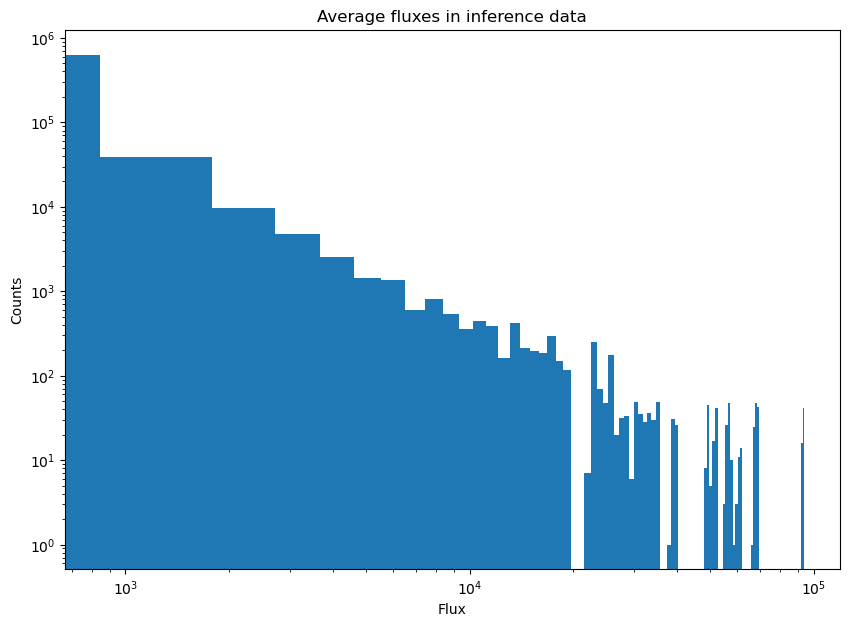

In [38]:
plt.hist(fluxes_no_29[1], bins=100)
plt.title('Average fluxes in inference data')
plt.xlabel('Flux')
plt.ylabel('Counts')
plt.yscale('log')
plt.xscale('log')
plt.show()


In [ ]:
#in the meantime, let's check on...the efficiency data ig? 
#to figure out how well we do as a function of brightness
#how do we not have lcs of eff data
#we must cause i literally have a script for that
#okay yeah it's in 
#/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/lightcurves_pos/
#are we worried about the average getting higher cause of our implanted transients?
#for now let's....not worry about it

In [43]:
save_name='offset_sat_newhparam_b50_allstamps_satdumbsplit_folds'

In [90]:
df_implants_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/df_implants_neg")
df_implants_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_pos/df_implants_pos")


In [71]:
len(df_implants_pos)

800

In [69]:
negdir = "/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_neg/predsarrays_average/"

In [70]:
def get_efficiency(df, df_implant, distance_threshold, posneg):
    df_cut = df[df['dist_to_implant']<=distance_threshold]
    df_cut = df_cut[df_cut['type']==posneg]
    df_cut.drop_duplicates(subset=["filename", "quad", "type","row_from_implant", "col_from_implant"], inplace=True)
    return len(df_cut),len(df_implant)

In [76]:
thr = "0.99"
test_name = "average"

In [77]:
df_pos = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'pos'+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)
df_neg = pd.read_csv("/lustre/lrspec/ZTF_data/efficiency_testing/nosat_eff_data/full_image_implantations_"+'neg'+"/predsarrays_"+test_name+"/df_matched_thr_"+thr)


In [78]:
df_implants_neg

,Unnamed: 0,filename,row_from_implant,col_from_implant,A_from_implant,sig_from_implant,quad_from_implant
0,0,ztf_20221020294271_000449_zr_c04_x_0004.,424.0,113.0,0.950,7.0,3
1,1,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,696.0,0.600,6.0,3
2,2,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,1199.0,0.990,9.0,3
3,3,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,1840.0,0.400,7.0,3
4,4,ztf_20221020294271_000449_zr_c04_x_0004.,425.0,2410.0,0.600,5.0,3
...,...,...,...,...,...,...,...
795,795,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,120.0,0.950,5.0,3
796,796,ztf_20221020154120_000640_zi_c03_x_0002.,3000.0,685.0,0.995,4.0,3
797,797,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1240.0,0.950,4.0,3
798,798,ztf_20221020154120_000640_zi_c03_x_0002.,2999.0,1843.0,0.400,7.0,3


In [120]:
def get_lcpath_from_eff_df_row(df_row, posneg):
    dir_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
    filename = df_row['filename']
    quad = df_row['quad_from_implant']
    lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(quad)+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+".csv"
    return(os.path.join(dir_path, lc_filename))

In [ ]:
#okay so we gotta make those light curves

In [ ]:
'lightcurve_ztf_20221020154120_000640_zi_c03_x_0002._2.npy_2_0007_2959.csv'

In [123]:
get_lcpath_from_eff_df_row(df_implants_pos_use.iloc[2], 'pos')

'/lustre/lrspec/ZTF_data/lightcurves/1020/lightcurve_ztf_20221020138241_000686_zi_c05_x_0000_3_0165_0695.csv'

In [116]:
#so what we need to do is calculate the average (bg subtracted) flux for all of those guys
#which we did, more or less
#but now we need to match it to the lc coordinates
posneg='neg'
for i, row in df_implants_neg_use.iterrows():
    lcpath = get_lcpath_from_eff_df_row(row, posneg)
    lc = pd.read_csv(lcpath)['flux_hap_2']
    df_implants_neg_use.loc[i, 'avg_flux']=np.average(lc)

/tmp/ipykernel_64034/4169214350.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_implants_neg_use.loc[i, 'avg_flux']=np.average(lc)


In [ ]:
#okay so we SHOULDNET do that
#instead let's look at the original LCs and use the flux values on those

(array([365., 160.,  60.,  45.,  35.,  15.,  45.,  30.,  10.,  20.]),
 array([0.0231448 , 0.23904457, 0.45494434, 0.67084411, 0.88674388,
        1.10264364, 1.31854341, 1.53444318, 1.75034295, 1.96624272,
        2.18214249]),
 <BarContainer object of 10 artists>)

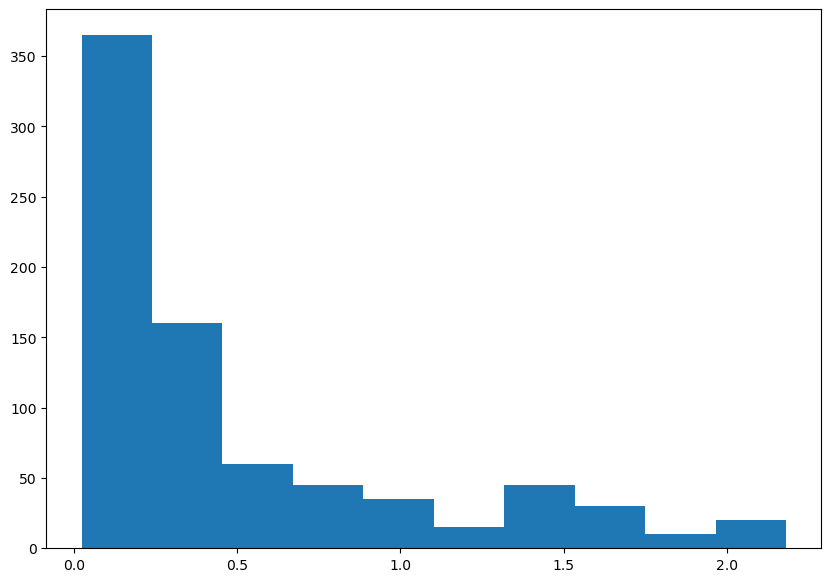

In [117]:
plt.hist(df_implants_neg_use['avg_flux'])

In [112]:
df_implants_neg_use = df_implants_neg[np.abs(df_implants_neg['Diff'])<20]

In [113]:
df_implants_pos_use = df_implants_pos[np.abs(df_implants_pos['Diff'])<20]

In [114]:
len(df_implants_pos_use), len(df_implants_pos)

(785, 800)

In [94]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [101]:
df_implants_pos = rff.match_stars_eff(df_implants_pos)

/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
3
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6
/lustre/lrspec/ZTF_data/corrected_coordinates/xy_arrays/ztf_20221020138241_000686_zi_c05_x_3.fits
6


In [99]:
%matplotlib inline

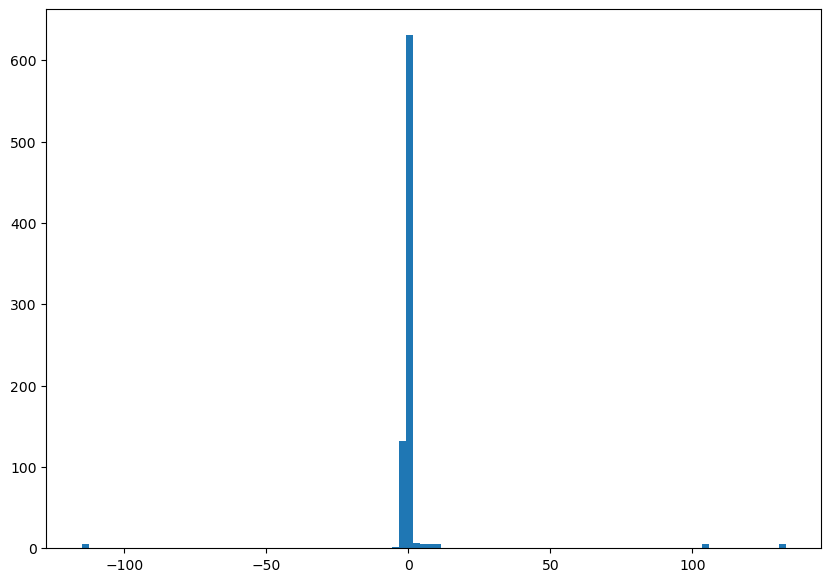

In [104]:
plt.hist(df_implants_neg['Diff'], bins=100)
plt.show()

In [ ]:
#okay so the right way to do it would be to take the average without the transient
#of the training data
#cause there isn't that much eff data i don't really trust it
#so the question is how hard is it to get to the original lc from the training data stamps
#answer: relies on redoing a bunch of stuff that should be fixed but...
#let's just extrapolate from the numbers and it'll be slightly wrong, for now

In [47]:
our_targ_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_targ_te_"+save_name+".npy") 
targ_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/targ_te_"+save_name+".npy") 
our_feat_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_feat_te_"+save_name+".npy")

In [53]:
our_feat_te = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_feat_te_"+save_name+".npy")
our_pred_te_max = np.load("/lustre/lrspec/ZTF_data/saved_loss/our_pred_te_max_"+save_name+'.npy') #NOTE ITS MAX

In [51]:
our_targ_te.shape

(28700,)

In [55]:
our_pred_te_max.shape

(28700,)

In [91]:
def get_avg_streak_from_stamp(stamp):
    argmax_to_get_middle = np.argmax(np.average(stamp, axis=0))
    lc = np.sum(stamp[:,argmax_to_get_middle-2:argmax_to_get_middle+3], axis=1)
    avg= np.average(lc)
    extrapolated_average = avg*(3080/len(lc))
    return extrapolated_average

In [71]:
stamp = our_feat_te[1]

In [89]:
argmax_to_get_middle = np.argmax(np.average(stamp, axis=0))
lc = np.sum(stamp[:,argmax_to_get_middle-2:argmax_to_get_middle+3], axis=1)
avg= np.average(lc)
extrapolated_average = avg*(3080/len(lc))

In [90]:
extrapolated_average

111.53821076750755

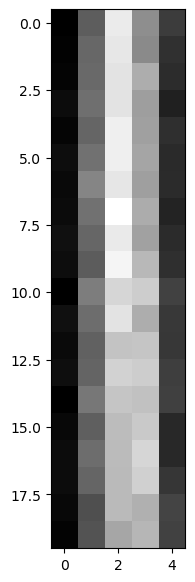

In [79]:
plt.imshow(stamp[:,argmax_to_get_middle-2:argmax_to_get_middle+3])

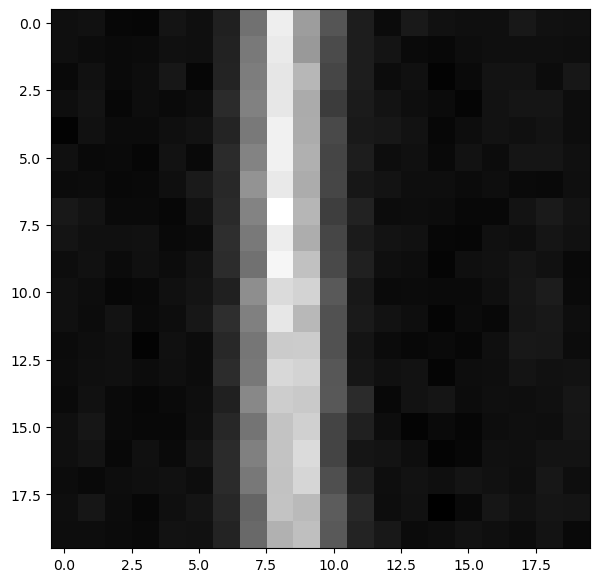

In [74]:
plt.imshow(our_feat_te[1])

In [94]:
avgs = []
for i, stamp in enumerate(our_feat_te):
    avg = get_avg_streak_from_stamp(stamp)
    avgs.append(avg)

In [99]:
np.min(avgs)

0.0

In [104]:
right_or_not = []
for i, number in enumerate(our_pred_te_max):
    if number==our_targ_te[i]:
        right_or_not.append(1)
    else:
        right_or_not.append(0)

In [124]:
right_or_not_pos = []
for i, number in enumerate(our_pred_te_max):
    if our_targ_te[i]==1:
        if number==our_targ_te[i]:
            right_or_not_pos.append(1)
        else:
            right_or_not_pos.append(0)

In [ ]:
avgs_pos = []
for i, stamp in enumerate(our_feat_te):
    if our_targ_te[i]==1:
        avg = get_avg_streak_from_stamp(stamp)
        avgs_pos.append(avg)

In [132]:
get_avg_streak_from_stamp(stamp)

144.31950381472709

In [137]:
np.array(right_or_not_pos)==1

array([ True, False,  True, ...,  True,  True,  True])

In [135]:
[right_or_not_pos==1]

array([], shape=(0, 14350), dtype=float64)

In [144]:
len(np.array(avgs_pos)[np.array(right_or_not_pos)==1])

10253

In [145]:
len(np.array(avgs_pos)[np.array(right_or_not_pos)==0])

4097

In [169]:
b1.shape

(30,)

In [167]:
(n1/(n1+n2)).shape

(29,)

Text(0.5, 1.0, 'brightness (incorrectly calculated) vs percentage correct per bin')

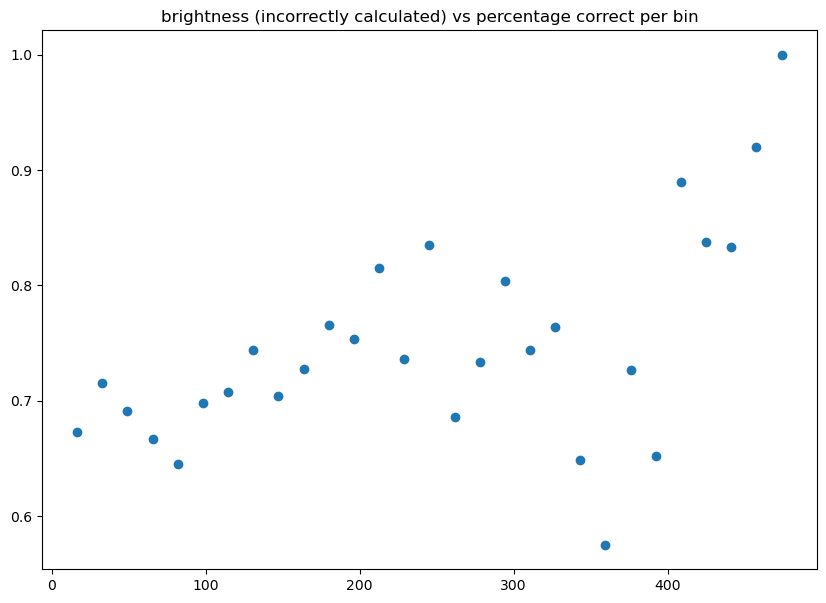

In [172]:
plt.scatter(b1[1:], n1/(n1+n2))
plt.title('brightness (incorrectly calculated) vs percentage correct per bin')

In [160]:
bins = np.linspace(np.min(avgs_pos), np.max(avgs_pos), 30)

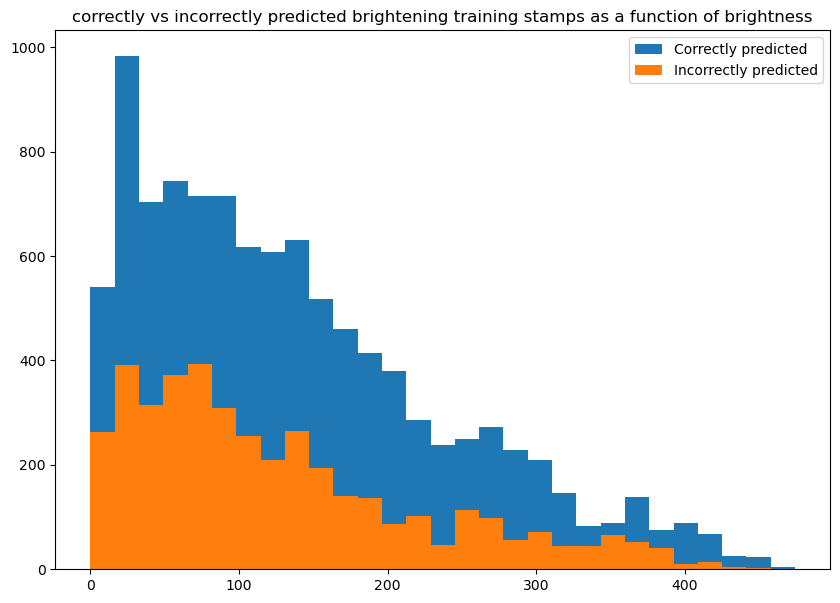

In [161]:
n1, b1, other = plt.hist(np.array(avgs_pos)[np.array(right_or_not_pos)==1], bins=bins, label="Correctly predicted")
n2, b2, other = plt.hist(np.array(avgs_pos)[np.array(right_or_not_pos)==0], bins=bins, label="Incorrectly predicted")

plt.title("correctly vs incorrectly predicted brightening training stamps as a function of brightness")
plt.legend()
plt.show()

Text(0.5, 1.0, 'color is whether it was predicted correctly or not')

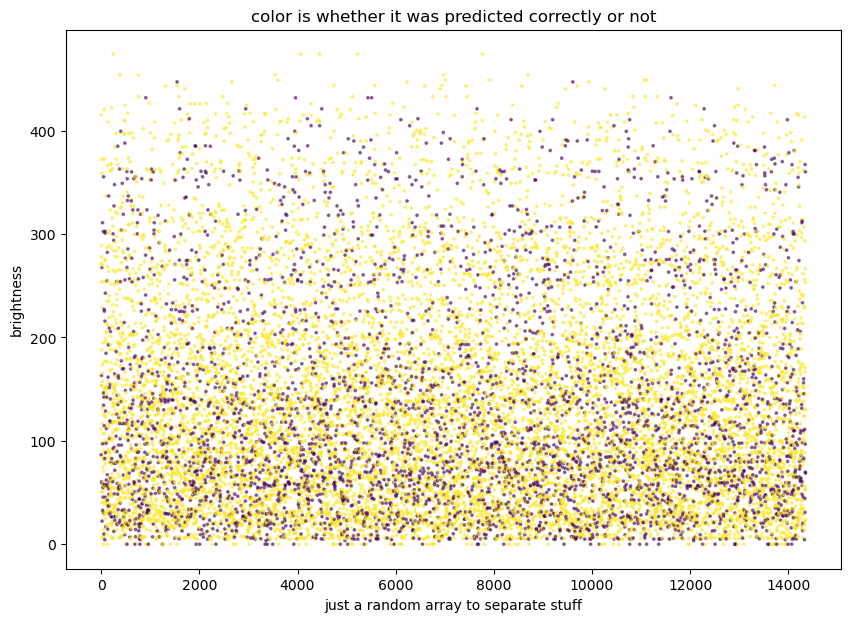

In [128]:
plt.scatter(np.linspace(0, len(right_or_not_pos),len(right_or_not_pos)),avgs_pos, c=right_or_not_pos, cmap='viridis',alpha=.5, s=3)
plt.xlabel('just a random array to separate stuff')
plt.ylabel('brightness')
plt.title('color is whether it was predicted correctly or not')

Text(0.5, 1.0, 'color is whether it was predicted correctly or not')

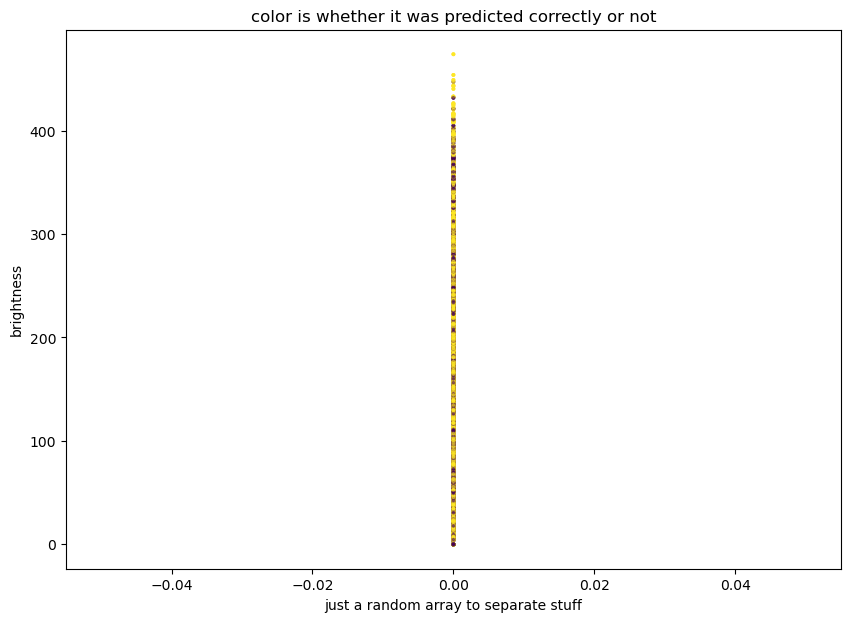

In [121]:
plt.scatter(np.linspace(0, 0,len(avgs)),avgs, c=right_or_not, cmap='viridis',alpha=.5, s=3)
plt.xlabel('just a random array to separate stuff')
plt.ylabel('brightness')
plt.title('color is whether it was predicted correctly or not')

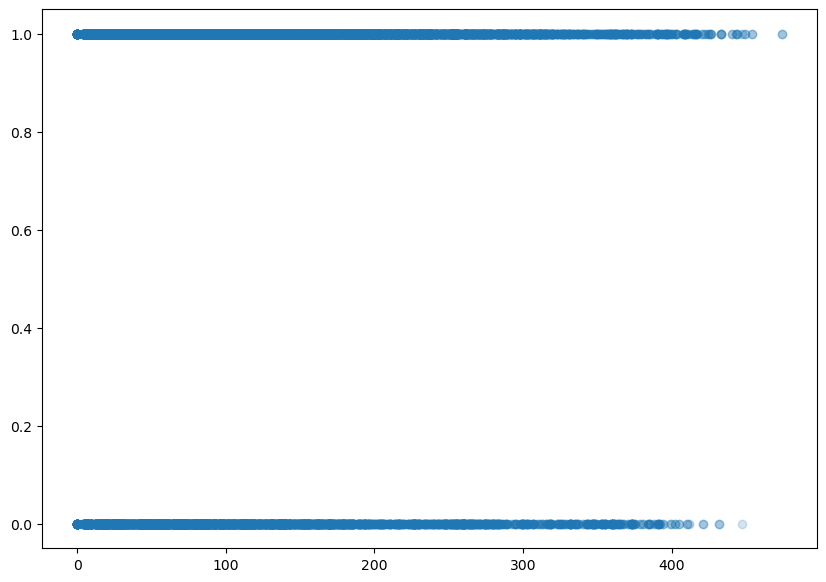

In [107]:
plt.scatter(avgs,right_or_not, alpha=.1)

(array([300., 735., 470., 756., 933., 789., 765., 527., 589., 687., 699.,
        706., 718., 767., 708., 694., 703., 630., 647., 628., 551., 461.,
        523., 640., 504., 502., 463., 517., 476., 524., 498., 343., 435.,
        401., 391., 386., 332., 320., 310., 301., 327., 286., 306., 226.,
        201., 255., 189., 215., 198., 232., 189., 147., 184., 295., 194.,
        206., 156., 198., 152., 148., 155.,  73., 124., 139.,  98., 108.,
         93.,  80.,  73.,  88.,  61.,  55.,  55.,  80.,  70.,  80., 101.,
         55.,  85.,  30.,  27.,  35.,  62.,  40.,  35.,  15.,  40.,  30.,
         10.,  20.,   0.,  15.,   5.,  10.,  10.,   5.,   0.,   0.,   0.,
          5.]),
 array([  0.        ,   4.74022865,   9.4804573 ,  14.22068595,
         18.9609146 ,  23.70114324,  28.44137189,  33.18160054,
         37.92182919,  42.66205784,  47.40228649,  52.14251514,
         56.88274379,  61.62297243,  66.36320108,  71.10342973,
         75.84365838,  80.58388703,  85.32411568,  90.06434433

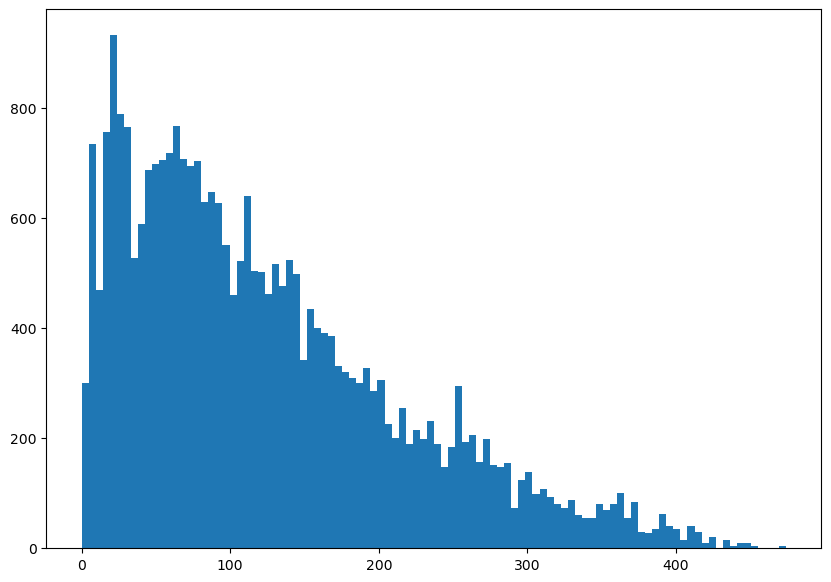

In [101]:
plt.hist(avgs, bins=100)

In [138]:
np.load("/lustre/lrspec/ZTF_data/saved_loss/"+save_name+"_info_te.npy")

array([[ 647,    0,    0, 2427,  331,    1],
       [ 382,    0,    4,  661,  799,    0],
       [ 476,    1,    9, 1574, 2757,    2],
       ...,
       [1099,    0,    0,  840, 1340,    0],
       [2460,    0,    0,  307,  230,  -12],
       [ 349,    0,    0, 1374, 1325,    2]])

In [ ]:
#okay so anyway we're gonna check the snr distributions for each 

In [143]:
fluxes_no_29

,0,1
0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.2234773710177
1,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,134.01331253547173
2,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,68.94194593058003
3,lightcurve_ztf_20221020138241_000686_zi_c04_x_...,33.9270216112013
4,lightcurve_ztf_20221020163819_000640_zg_c10_x_...,90.0123512416691
...,...,...
723141,lightcurve_ztf_20221020138241_000686_zi_c13_x_...,81.27483291625977
723142,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,2904.682248677836
723143,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,99.94683338016658
723144,lightcurve_ztf_20221020163819_000640_zg_c16_x_...,106.90212204673074


In [144]:
rf_gone = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/rf_gone_with_brightness_ranking')

In [145]:
rf_gone['concat_index_copy']=rf_gone['Unnamed: 0.3']

In [148]:
len(rf_gone)

342433

In [151]:
to_keep = []
not_keep = []
for i, row in rf_gone.iterrows():
    # print(row['filename'][-5:])
    if row['filename'][-5:]!='0029.':
        to_keep.append(i)
    else:
        not_keep.append(i)
        

In [152]:
np.max(to_keep)

342432

In [153]:
len(to_keep)

325727

In [61]:
rf_gone['concat_index_copy']

KeyError: 'concat_index_copy'

In [155]:
rf_gone_no_0029 = rf_gone.loc[to_keep]

In [156]:
len(rf_gone_no_0029)

325727

In [93]:
def make_filename(df_row):
    return 'lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quad'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+'.csv'

In [161]:
rf_gone_no_0029['lc_filename']=make_filename(rf_gone_no_0029)

TypeError: cannot convert the series to <class 'int'>

In [164]:
for i, df_row in rf_gone_no_0029.iterrows():
    rf_gone_no_0029.loc[i,'lc_filename'] = make_filename(df_row)


KeyboardInterrupt



In [165]:
rf_gone_no_0029['lc_filename'] = rf_gone_no_0029.apply(make_filename, axis=1)

In [167]:
rf_gone_no_0029

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result,brightness_ranking,concat_index_copy,lc_filename
0,0,0,0,0,0,0,0,0,0,0,...,690.0,0.120616,0.145088,pos,pos,138.500000,0.0,0.0,0,lightcurve_ztf_20221020141806_000686_zi_c11_x_...
1,1,1,1,1,1,1,1,1,1,1,...,1160.0,0.163725,0.148208,neg,neg,-338.312500,0.0,0.0,1,lightcurve_ztf_20221020141806_000686_zi_c11_x_...
2,2,2,2,2,2,2,2,2,2,2,...,2070.0,0.507125,0.409946,pos,pos,-1255.173913,0.0,0.0,2,lightcurve_ztf_20221020141806_000686_zi_c11_x_...
3,3,3,3,3,3,3,3,3,3,3,...,2461.0,0.190395,0.198984,pos,pos,-1632.625000,0.0,0.0,3,lightcurve_ztf_20221020141806_000686_zi_c11_x_...
4,4,4,4,4,4,4,4,4,4,4,...,2562.0,0.191027,0.187296,neg,neg,-1736.500000,0.0,0.0,4,lightcurve_ztf_20221020141806_000686_zi_c11_x_...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
342428,347419,347419,347419,347419,347419,347419,347419,347419,347419,49,...,833.0,0.377672,0.401030,neg,neg,625.500000,0.0,2.0,347419,lightcurve_ztf_20221020157697_000640_zi_c05_x_...
342429,347420,347420,347420,347420,347420,347420,347420,347420,347420,50,...,1253.0,0.918655,0.889413,neg,neg,-388.214286,0.0,12.0,347420,lightcurve_ztf_20221020157697_000640_zi_c05_x_...
342430,347421,347421,347421,347421,347421,347421,347421,347421,347421,51,...,1338.0,0.845833,0.911684,pos,pos,-491.156250,0.0,12.0,347421,lightcurve_ztf_20221020157697_000640_zi_c05_x_...
342431,347422,347422,347422,347422,347422,347422,347422,347422,347422,0,...,834.0,0.283822,0.246317,pos,pos,1227.142857,0.0,0.0,347422,lightcurve_ztf_20221020294271_000449_zr_c04_x_...


In [170]:
merged = rf_gone_no_0029.merge(
    fluxes_no_29[[0, 1]],
    left_on='lc_filename',
    right_on=0,
    how='left'
)

In [174]:
merged[1]

0          6338.102613731483
1          6338.102613731483
2          6338.102613731483
3          6338.102613731483
4          6338.102613731483
                 ...        
325722    1001.8537897580629
325723     333.0202072539887
325724     333.0202072539887
325725    11144.724415330764
325726     513.6761924842735
Name: 1, Length: 325727, dtype: object

In [179]:
merged[1] = merged[1].astype(float)

In [187]:
less_than_130 = merged[merged[1]<130]
more_than_130 = merged[merged[1]>130]


Text(0, 0.5, 'counts')

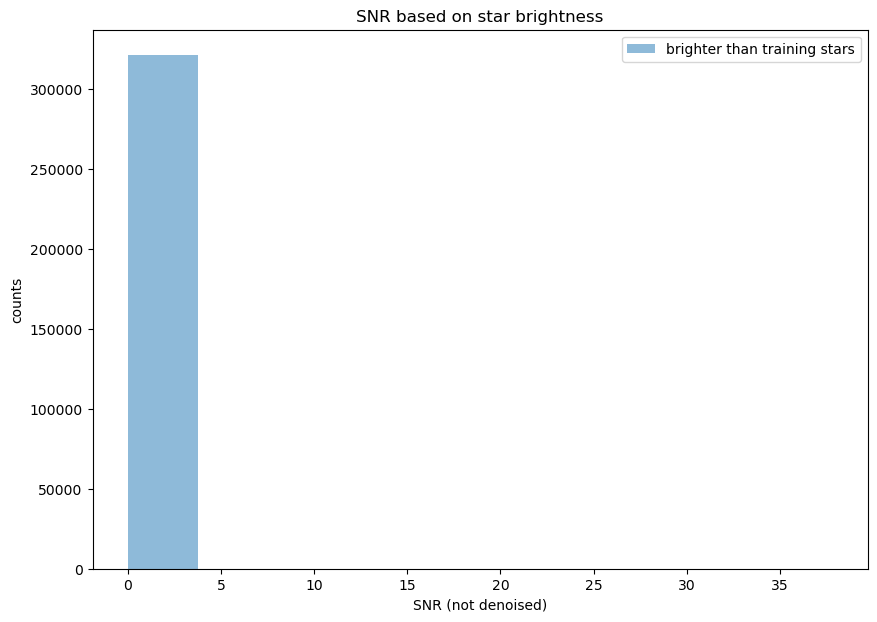

In [232]:
# plt.hist(less_than_130['snr_local'],  label='dimmer than training stars', alpha=.5, color='blue')
plt.hist(more_than_130['snr_local'],  label='brighter than training stars', alpha=.5)
# plt.xscale('log')
plt.legend()
plt.xlabel("SNR (not denoised)")
plt.title("SNR based on star brightness")
plt.ylabel("counts")


(-1.0, 5.0)

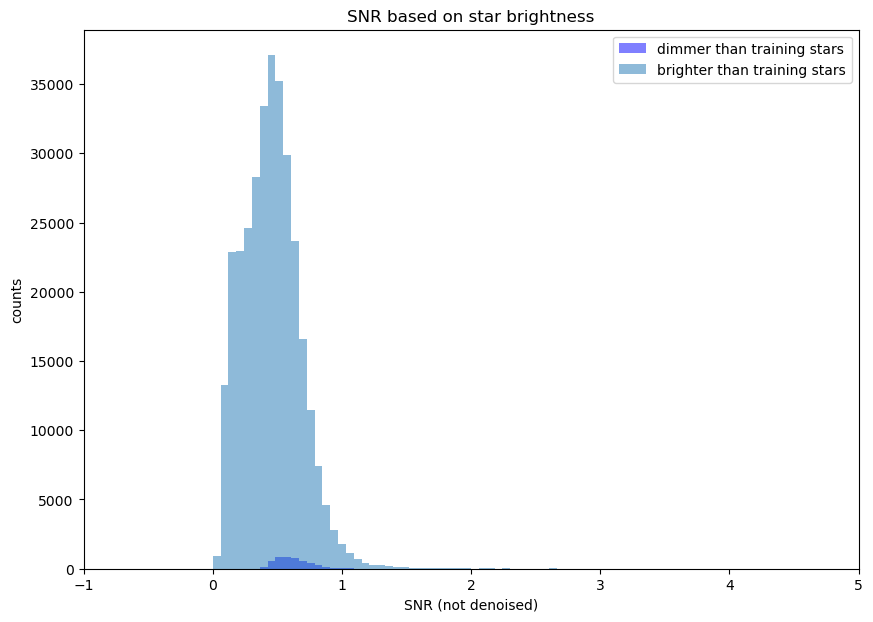

In [230]:
plt.hist(less_than_130['snr_local'], bins=np.linspace(0,6,100), label='dimmer than training stars', alpha=.5, color='blue')
plt.hist(more_than_130['snr_local'], bins=np.linspace(0,6,100), label='brighter than training stars', alpha=.5)
# plt.xscale('log')
plt.legend()
plt.xlabel("SNR (not denoised)")
plt.title("SNR based on star brightness")
plt.ylabel("counts")
plt.xlim(-1,5)

In [2]:
import pandas as pd

In [5]:
import numpy as np

In [3]:
final_df = pd.read_csv('/lustre/lrspec/ZTF_data/final_df_august')

In [6]:
np.min(final_df['snr_local_denoised'])

1.5488569939297463

In [540]:
final_df.loc[64]['closest_x']

2551.0

In [236]:
final_df['concat_index_copy']

0     233662
1     252593
2      64793
3     265333
4     340170
       ...  
95    128618
96    199793
97    161233
98    343159
99      3910
Name: concat_index_copy, Length: 100, dtype: int64

In [240]:
rff.plot_lcs_together?

Signature:
rff.plot_lcs_together(
    *rowindex,
    df,
    time_adjusted=True,
    hap=2,
    xmin=None,
    xmax=None,
    zoom=None,
    use_snr_center=True,
)
Docstring:
plots light curve with transient candidates, color coded to
which part of the pipeline they were removed on
hap: half aperture for light curve, allowable from 2 to 5
File:      ~/rwe/review_findings_functions.py
Type:      function

In [251]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [248]:
rff.plot_lcs_simultaneous_with_spatial?

Signature:
rff.plot_lcs_simultaneous_with_spatial(
    rindex,
    indices,
    df,
    time_adjusted=True,
    hap=2,
    xmin=None,
    xmax=None,
    zoom=None,
    use_snr_center=True,
    number=6,
)
Docstring:
Plots the primary transient candidate light curve, all simultaneously-flagged
event LCs (highlighted with blue-ring markers), and the `number` spatially
nearest stars on each side (by x-position, pulled from the xy_arrays FITS
file since most aren't transient candidates in df). Skips neighbors whose
curve doesn't overlap the primary's highlighted time window, continuing to
further neighbors until `number` valid ones are found per side.
Stars with x < primary are plotted ABOVE, x >= primary plotted BELOW.
Each curve is annotated at the left edge with its x-distance from the
primary candidate's closest_x (signed, with left/right direction).
hap: half aperture for light curve, allowable from 2 to 5
number: how many spatial neighbors to plot on EACH side
File:      ~/rwe/review

In [279]:
final_df.loc[53]['filename']

'ztf_20221020157697_000640_zi_c01_x_0019.'

In [281]:
final_df.loc[53]['type']

'pos'

In [286]:
df = final_df
index = 53
nrow, ncol = 3080, 3072 
wid = 10
path = '/lustre/lrspec/ZTF_data/science_extractions/'+'1020april26/average'+'/'
pred = df.loc[index]["filename"]
extra = '_extraction_predsarray_'+str(df.loc[index,'quad'])+'_predsarray.npy'
print(path+pred+extra)
predsarray = np.load(path+pred+extra)
if df.loc[index, "type"]=="pos":
    pimg = predsarray[:, 1].reshape(ncol - 2 * wid, nrow - 2 * wid)
else:
    pimg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)

/lustre/lrspec/ZTF_data/science_extractions/1020april26/average/ztf_20221020157697_000640_zi_c01_x_0019._extraction_predsarray_2_predsarray.npy


In [336]:
path = '/lustre/lrspec/ZTF_data/2022/1020/ztf_20221020157697_000640_zi_c01_x_0019.fits.fz'
hdul = fits.open(path)
file1_array = hdul[2].data

In [368]:
%matplotlib inline

In [384]:
np.sum(pimg.T[:,1412-13:1412+5]>.99)

8

In [395]:
pimg_neg = predsarray[:, 2].reshape(ncol - 2 * wid, nrow - 2 * wid)

In [402]:
np.sum(pimg_neg.T[:,1412-13-10:1412+5-10]>.99)

1

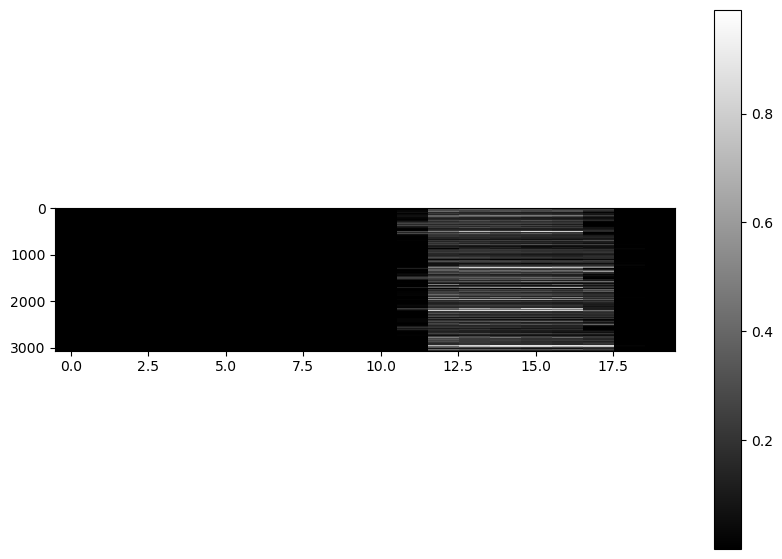

In [407]:
plt.imshow(pimg_neg.T[:,1412-15-10:1412+5-10], aspect=.0015)
plt.colorbar()

In [428]:
np.sum(pimg.T[:,1412-5-10:1412+5-10]>.99)

8

In [441]:
np.sum(pimg.T[:,1412+5-10:1412+15-10]>.8)

1

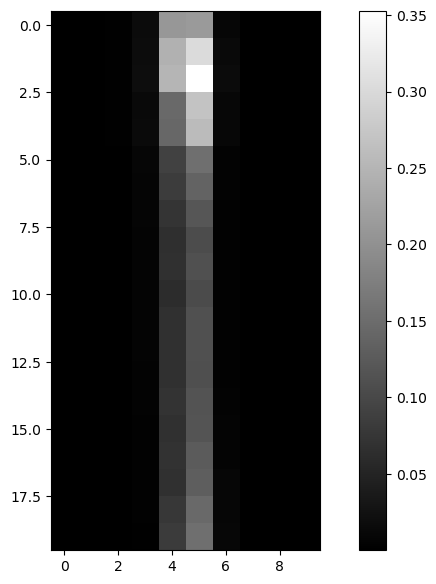

In [485]:
plt.imshow(pimg_neg.T[1320-stardiff:1340-stardiff,1412+5-10:1412+15-10])
plt.colorbar()

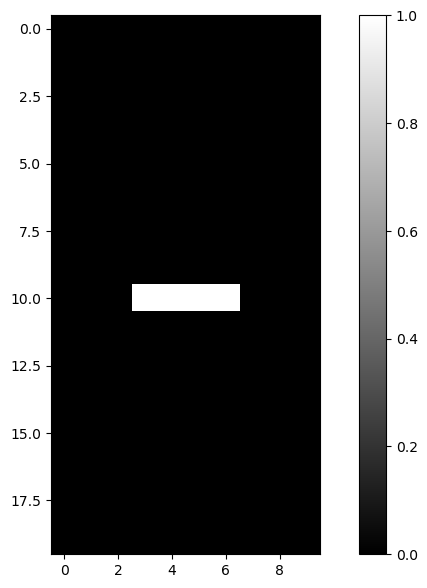

In [449]:
plt.imshow(pimg.T[1320:1340,1412-5-10:1412+5-10]>.99)
plt.colorbar()

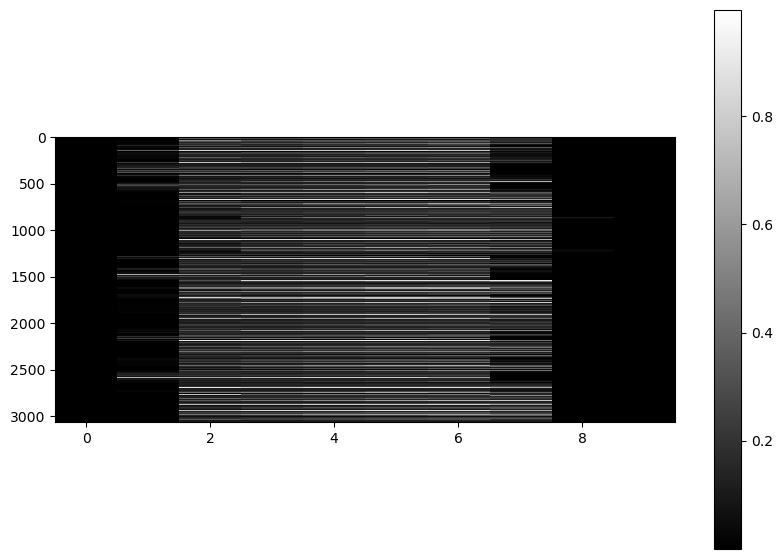

In [445]:
plt.imshow(pimg.T[:,1412-5-10:1412+5-10], aspect=.0015)
plt.colorbar()

In [468]:
%matplotlib inline

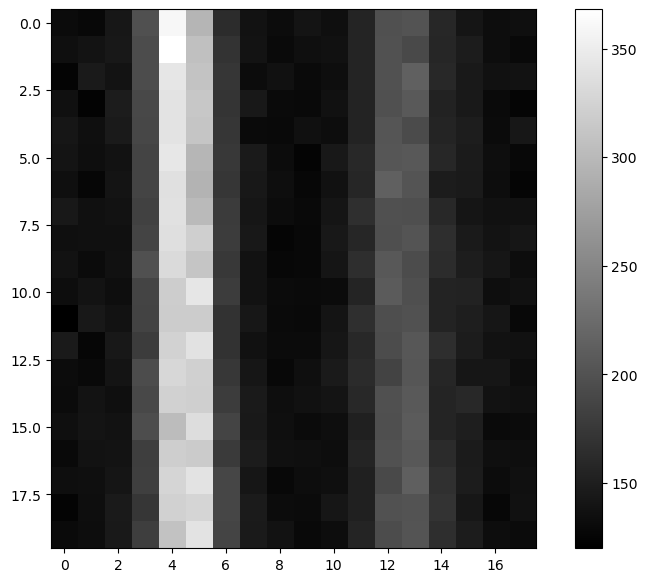

In [486]:
plt.imshow(file1_array[1330-stardiff:1350-stardiff,1412-5:1412+13])
plt.colorbar()
plt.show()

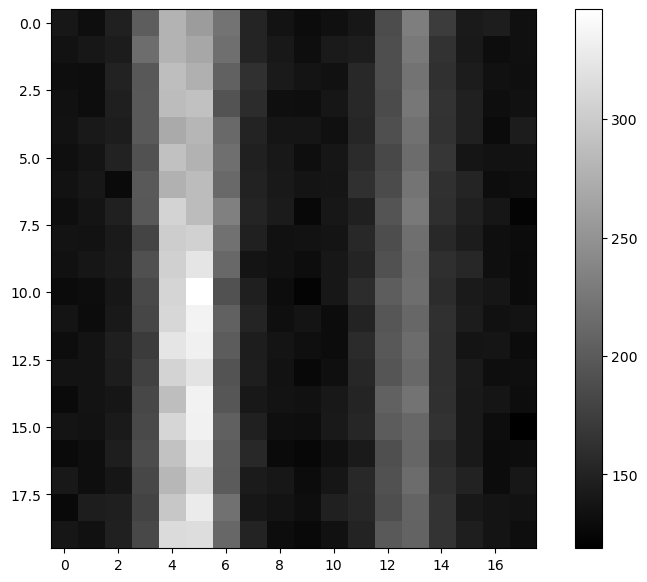

In [487]:
plt.imshow(file1_array[1330:1350,1412-5:1412+13])
plt.colorbar()
plt.show()

In [466]:
file1_array[1330:1350,1412-5:1412+13]

array([[139.73645 , 132.1876  , 148.79434 , 201.57724 , 278.7921  ,
        258.27527 , 221.66673 , 151.57475 , 135.86342 , 129.9949  ,
        133.95465 , 139.48508 , 187.18971 , 230.97495 , 172.44606 ,
        142.57164 , 145.50668 , 133.54309 ],
       [135.182   , 139.47032 , 144.35028 , 216.5377  , 278.8541  ,
        267.91446 , 217.7105  , 151.3603  , 140.34346 , 131.69795 ,
        142.32468 , 145.2192  , 188.31564 , 227.98445 , 164.15103 ,
        141.47592 , 131.1397  , 133.40982 ],
       [131.75623 , 130.41995 , 149.55429 , 197.25403 , 288.22812 ,
        275.51892 , 205.82681 , 161.52641 , 142.04677 , 137.14948 ,
        134.47734 , 155.51364 , 188.56113 , 221.79941 , 161.93481 ,
        144.00038 , 134.0735  , 132.2079  ],
       [134.6745  , 130.7552  , 146.47061 , 198.59747 , 286.03268 ,
        290.87656 , 192.9829  , 159.51608 , 133.03384 , 131.71042 ,
        139.09447 , 154.75887 , 185.61346 , 224.94926 , 164.94034 ,
        147.9347  , 132.04907 , 134.19934 ],
    

In [471]:
stardiff = 1091-209

In [490]:
stardiff

882

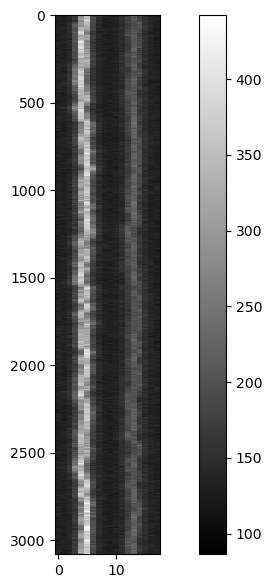

In [489]:
plt.imshow(file1_array[:,1412-5:1412+13], aspect=.03)
plt.colorbar()

(2000.0, 2500.0)

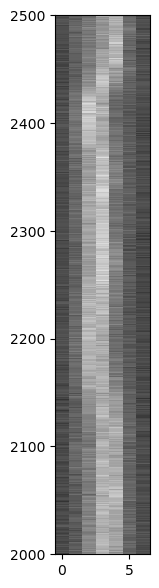

In [538]:
plt.imshow(file1_array[:,1412+5:1412+12], aspect=.08)
plt.ylim(2000,2500)

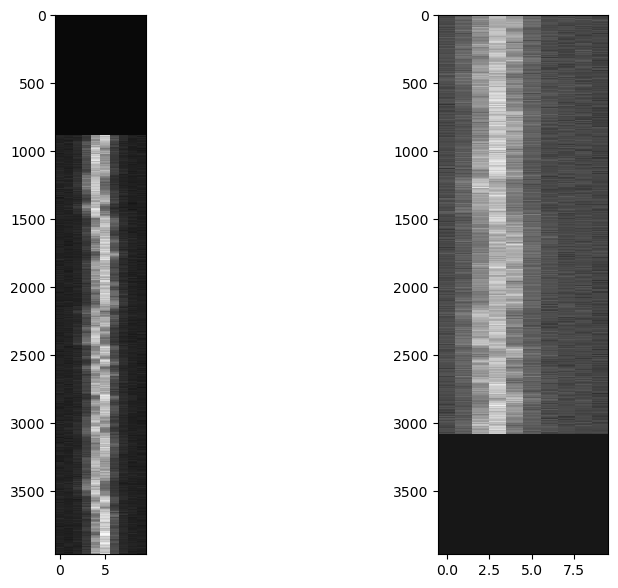

In [532]:
fig, ax = plt.subplots(1,2)
ax[0].imshow(np.vstack((np.full((stardiff,10),100),file1_array[:,1412-5:1412+5])), aspect=.015)
ax[1].imshow(np.vstack((file1_array[:,1412+5:1412+15],np.full((stardiff,10),100))), aspect=.008)

In [427]:
final_df.loc[53,'original_cols_from_nn']

'[1330.]'

In [454]:
final_df.columns[30:]

Index(['noise_local_brightening', 'noise_global_brightening',
       'local_average_outside_brightening', 'height_brightening',
       'FWHM_brightening', 'signal_local_brightening',
       'central_point_brightening', 'snr_local_dimming', 'snr_global_dimming',
       'noise_local_dimming', 'noise_global_dimming',
       'local_average_outside_dimming', 'height_dimming', 'FWHM_dimming',
       'signal_local_dimming', 'central_point_dimming', 'quadrant',
       'num_in_file_in_star', 'Band', 'snr_local_brightening_filtered2',
       'snr_global_brightening_filtered2', 'noise_local_brightening_filtered2',
       'noise_global_brightening_filtered', 'height_brightening_filtered2',
       'FWHM_brightening_filtered2', 'signal_local_brightening_filtered',
       'central_point_brightening_filtere', 'snr_local_dimming_filtered2',
       'snr_global_dimming_filtered2', 'noise_local_dimming_filtered2',
       'noise_global_dimming_filtered', 'height_dimming_filtered2',
       'FWHM_dimming_fil

In [458]:
final_df.loc[53]['distance_from_start']

-1131.0

In [372]:
final_df.loc[53]['lc_filename']

'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1412_0209.csv'

In [482]:
stardiff

882

In [523]:
lc_small = pd.read_csv('/lustre/lrspec/ZTF_data/lightcurves/1020/lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1420_1091.csv')

Text(0.5, 1.0, 'central column for light curve extraction')

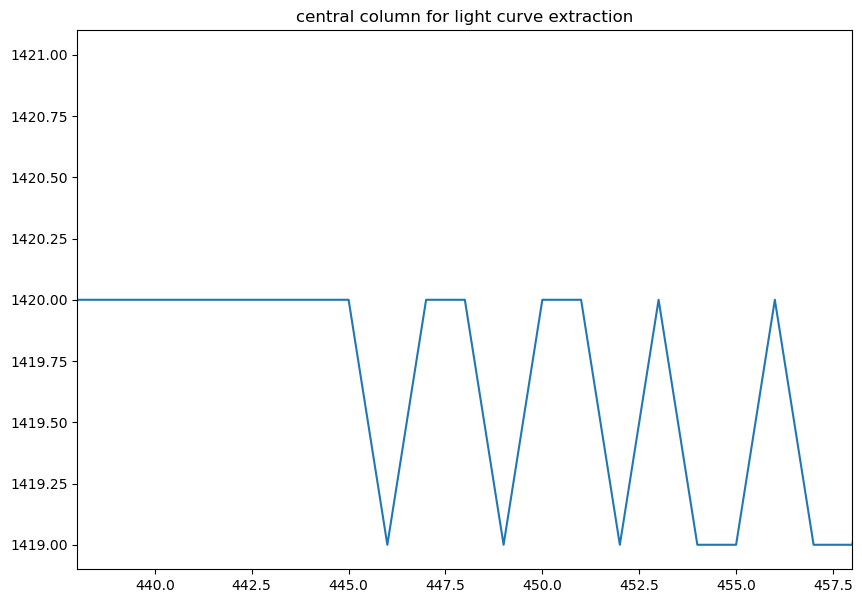

In [530]:
plt.plot(lc_small['max_col'])
plt.xlim(1320-stardiff,1340-stardiff)
plt.title("central column for light curve extraction")

In [481]:
#that light curve:
lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1420_1091.csv
#so to line it up with 0209 it would be minus 1091
#star starts later so we should look at it later: 1091-209
#star A stars near the top of the page
#star B starts near the bottom of the page
#to line up A and B, we must move B up or A down
#but the interval should be the same: 209 + x = constant and 1091 + y = constant
#so y = 209+x-1091 = x -stardiff

NameError: name 'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1420_1091' is not defined

In [325]:
np.sum(pimg.T[:,int((final_df.loc[53]['col_from_nn']+wid))-10:int(final_df.loc[53]['col_from_nn']+wid)+10]>.99)

6

In [460]:
rf_gone_no_0029[(rf_gone_no_0029['filename']==final_df.loc[53]['filename'])*(rf_gone_no_0029['quad']==final_df.loc[53]['quad'])]['distance_from_start']

188638    2949.000000
188639    2017.000000
188640    1158.000000
188641     444.000000
188642   -1341.500000
188643    2154.000000
188644     199.000000
188645   -1131.000000
188646    2464.000000
188647    2760.000000
188648    1169.666667
188649    2467.000000
188650    1017.000000
188651   -1171.000000
188652    1309.000000
188653   -1024.000000
188654    2165.083333
188655    1283.000000
188656     301.000000
188657    1511.000000
188658    -293.142857
188659     772.000000
188660     829.000000
188661    1717.000000
188662    -638.000000
188663     144.000000
Name: distance_from_start, dtype: float64

In [334]:
rf_gone_no_0029[(rf_gone_no_0029['filename']==final_df.loc[53]['filename'])*(rf_gone_no_0029['quad']==final_df.loc[53]['quad'])]['lc_filename'].values

array(['lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_0068_2959.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_0068_2959.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_0111_1168.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_0138_0454.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_0138_0454.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_0284_2164.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1412_0209.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1412_0209.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1537_2474.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1648_2770.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1648_2770.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1709_2477.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1789_1027.csv',

In [332]:
rf_gone_no_0029[(rf_gone_no_0029['filename']==final_df.loc[53]['filename'])*(rf_gone_no_0029['quad']==final_df.loc[53]['quad'])]

,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,...,central_point_dimming_f3,snr_local,snr_global,real_type_local,real_type_global,distance_from_start,random_forest_result,brightness_ranking,concat_index_copy,lc_filename
188638,191326,191326,191326,191326,191326,191326,191326,191326,191326,0,...,-10.0,0.264041,0.225445,pos,pos,2949.000000,0.0,22.0,191326,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
188639,191327,191327,191327,191327,191327,191327,191327,191327,191327,1,...,941.0,0.518773,0.485554,neg,neg,2017.000000,0.0,22.0,191327,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
188640,191328,191328,191328,191328,191328,191328,191328,191328,191328,2,...,-10.0,0.373280,0.341469,pos,pos,1158.000000,0.0,19.0,191328,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
188641,191329,191329,191329,191329,191329,191329,191329,191329,191329,3,...,-10.0,0.567852,0.470091,pos,pos,444.000000,0.0,11.0,191329,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
188642,191330,191330,191330,191330,191330,191330,191330,191330,191330,4,...,1776.0,0.549587,0.576707,pos,pos,-1341.500000,0.0,11.0,191330,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
188643,191331,191331,191331,191331,191331,191331,191331,191331,191331,5,...,-10.0,0.365899,0.350797,pos,pos,2154.000000,0.0,15.0,191331,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
188644,191332,191332,191332,191332,191332,191332,191332,191332,191332,6,...,-10.0,0.260171,0.227622,pos,pos,199.000000,0.0,10.0,191332,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
188645,191333,191333,191333,191333,191333,191333,191333,191333,191333,7,...,1320.0,1.672742,1.681051,neg,neg,-1131.000000,0.0,10.0,191333,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
188646,191334,191334,191334,191334,191334,191334,191334,191334,191334,8,...,-10.0,0.395367,0.329427,pos,pos,2464.000000,0.0,6.0,191334,lightcurve_ztf_20221020157697_000640_zi_c01_x_...
188647,191335,191335,191335,191335,191335,191335,191335,191335,191335,9,...,-10.0,0.554618,0.541544,pos,pos,2760.000000,0.0,23.0,191335,lightcurve_ztf_20221020157697_000640_zi_c01_x_...


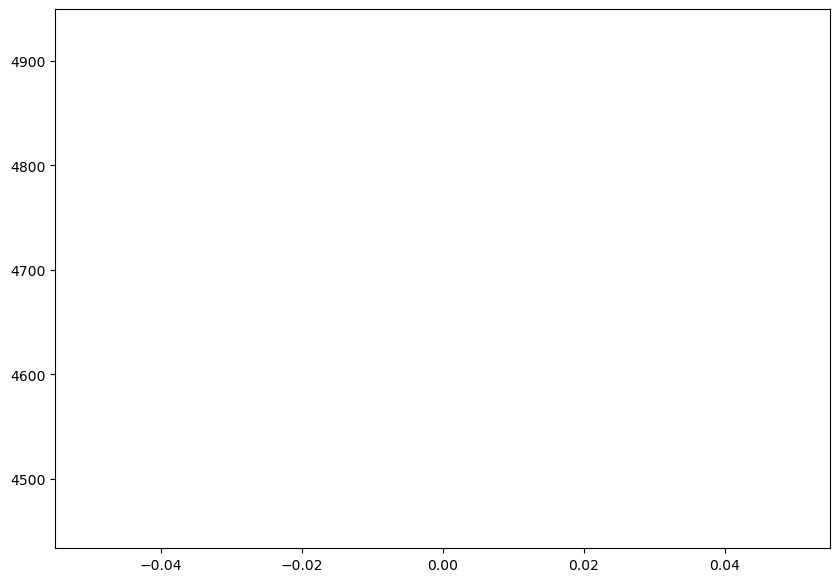

In [322]:
plt.plot(np.sum(pimg.T[:,int((final_df.loc[53]['col_from_nn']+wid))-20:int(final_df.loc[53]['col_from_nn']+wid)+20]))

In [315]:
np.sum(pimg.T[:,int((final_df.loc[53]['col_from_nn']+wid))-20:int(final_df.loc[53]['col_from_nn']+wid)+20]>.99)

8

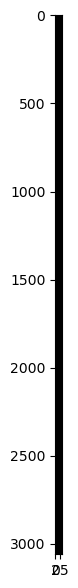

In [316]:
plt.imshow(pimg.T[:,int((final_df.loc[53]['col_from_nn']+wid))-20:int(final_df.loc[53]['col_from_nn']+wid)+20]>.99)

In [450]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [451]:
rff.plot_lcs_simultaneous_with_spatial(53, [],df=final_df, number=1, xmin=500, xmax=2000)

lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1339_2138.csv
lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1283_0312.csv
lightcurve_ztf_20221020157697_000640_zi_c01_x_0019_2_1420_1091.csv


lightcurve_ztf_20221020148032_000686_zg_c07_x_0028_1_2483_2959.csv
lightcurve_ztf_20221020148032_000686_zg_c07_x_0028_1_2565_0525.csv


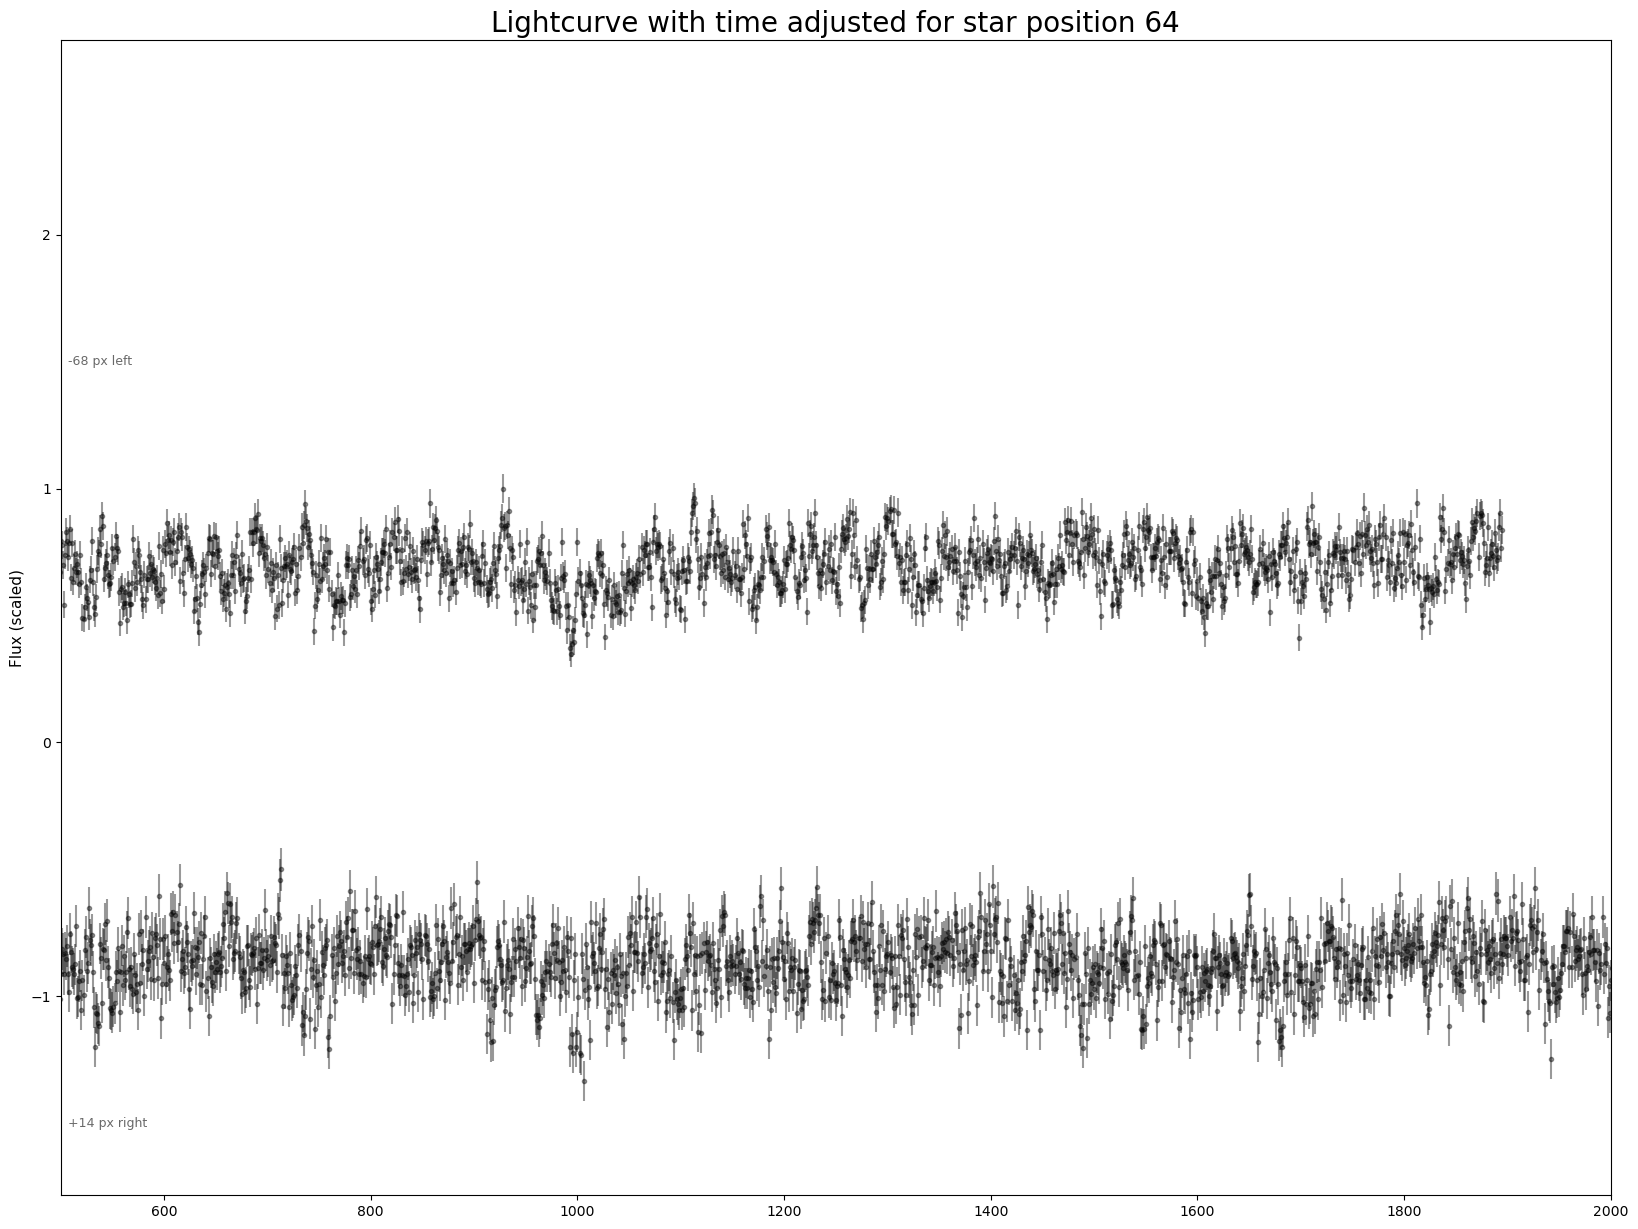

In [541]:
rff.plot_lcs_simultaneous_with_spatial(64, [],df=final_df, number=2, xmin=500, xmax=2000)

In [268]:
final_df['lc_filename'] = final_df.apply(make_filename, axis=1)

In [269]:
final_merge = final_df.merge(
    fluxes_no_29[[0, 1]],
    left_on='lc_filename',
    right_on=0,
    how='left'
)

In [274]:
np.min(final_merge[1].astype(float))

184.33879686826236

Text(0.5, 0, 'flux')

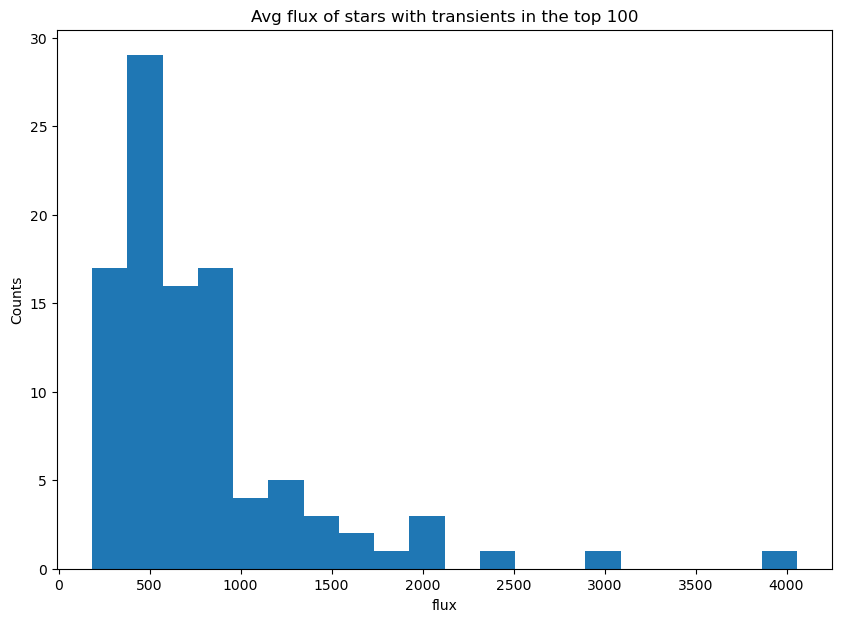

In [276]:
plt.hist(final_merge[1].astype(float), bins=20)
plt.title("Avg flux of stars with transients in the top 100")
plt.ylabel("Counts")
plt.xlabel("flux")

In [73]:
starhours=411514*10/3600 #including removing RF - see emrged df much lower

In [74]:
starhours2 = starhours-starhours*pixelstoSH(40)/pixelstoSH(3080)  #subtract 20 pixels on each side

In [75]:
starhours2

1128.249062049062

In [76]:
starhours2 - pixelstoSH(80)* (3970/31) #number of files #subtract beginning of crm pixels

1128.2398221849835

In [38]:
def pixelstoSH(pixels):
    seconds = pixels * 10/3080
    # print(seconds)
    SH = seconds/(60*60)
    # print(SH)
    return SH

In [17]:
pixelstoSH(80)* (1/29)

32.243618450515

In [ ]:
starhours*((3080-40)/3080)

<ErrorbarContainer object of 3 artists>

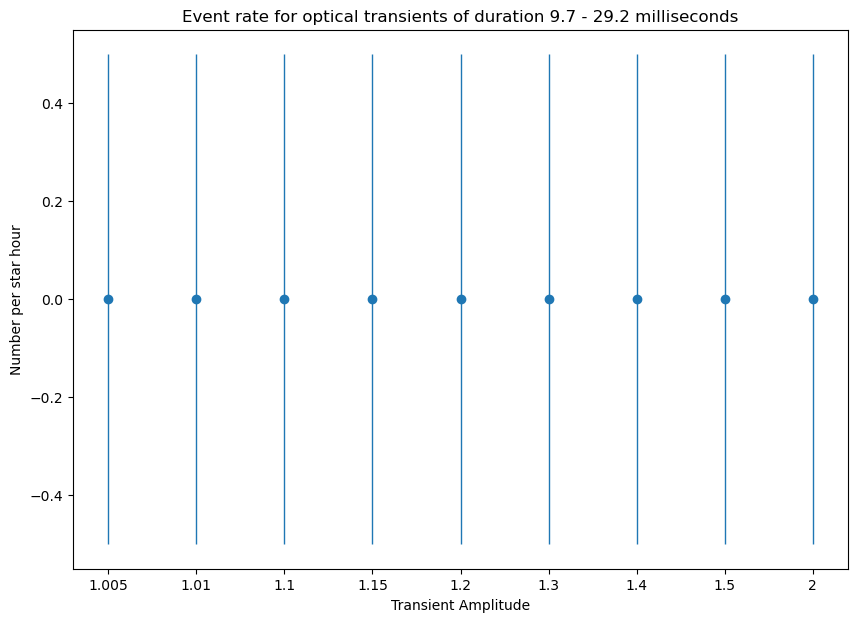

In [521]:
plt.title("Event rate for optical transients of duration 9.7 - 29.2 milliseconds")
plt.ylabel("Number per star hour")
plt.xlabel("Transient Amplitude") #let's do pos and neg separately
# amps = [1.005,1.01,1.1,1.15,1.2,1.3,1.4,1.5,2]
amps = ['1.005','1.01','1.1','1.15','1.2','1.3','1.4','1.5','2']
plt.errorbar(amps,np.zeros(len(amps)), np.full(len(amps),.5),ls='none',elinewidth=1,fmt='o')

In [55]:
predictions_file='/lustre/lrspec/ZTF_data/random_forest_training/predictions_updated.csv'
predictions = pd.read_csv(predictions_file, names=['filename', 'rf'])

In [57]:
predictions['filename'].values

array(['lightcurve_ztf_20221020138241_000686_zi_c11_x_0023_4_1499_1443.csv',
       'lightcurve_ztf_20221020148032_000686_zg_c13_x_0017_4_0671_2743.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0007_2_2443_0934.csv',
       ...,
       'lightcurve_ztf_20221020148032_000686_zg_c07_x_0020_4_3010_2091.csv',
       'lightcurve_ztf_20221020163819_000640_zg_c16_x_0025_1_0438_1552.csv',
       'lightcurve_ztf_20221020154120_000640_zi_c08_x_0001_1_2101_2252.csv'],
      dtype=object)

In [53]:
fluxes_no_29[0].values

array(['lightcurve_ztf_20221020138241_000686_zi_c11_x_0023_4_1499_1443.csv',
       'lightcurve_ztf_20221020148032_000686_zg_c13_x_0017_4_0671_2743.csv',
       'lightcurve_ztf_20221020157697_000640_zi_c01_x_0007_2_2443_0934.csv',
       ...,
       'lightcurve_ztf_20221020148032_000686_zg_c07_x_0020_4_3010_2091.csv',
       'lightcurve_ztf_20221020163819_000640_zg_c16_x_0025_1_0438_1552.csv',
       'lightcurve_ztf_20221020154120_000640_zi_c08_x_0001_1_2101_2252.csv'],
      dtype=object)

In [58]:
merged_lcs = predictions.merge(
    fluxes_no_29[[0, 1]],
    left_on='filename',
    right_on=0,
    how='left'
)

In [63]:
merged_lcs = fluxes_no_29.merge(
    predictions[['filename','rf']],
    left_on=0,
    right_on='filename',
    how='left'
)

In [65]:
len(merged_lcs), len(fluxes_no_29), len(predictions)

(698669, 698669, 723146)

In [77]:
lcs_no_rf_no_29 = merged_lcs[(merged_lcs['rf']==0)*(merged_lcs[1].astype(float)>130.61321985319063)]

In [78]:
lcs_no_rf_no_29

,0,1,filename,rf
0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.2234773710177,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,0
1,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,134.01331253547173,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0
5,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,603.2061236492999,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,0
11,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,152.50853827340262,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,0
13,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,946.5012182260489,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,0
...,...,...,...,...
698659,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,5955.066167816559,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,0
698661,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1057.229435809247,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,0
698662,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,2374.9911632983717,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,0
698663,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,164.74849453715535,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,0


In [85]:
df_row['filename']

'lightcurve_ztf_20221020138241_000686_zi_c11_x_0023_4_1499_1443.csv'

In [84]:
df_row = lcs_no_rf_no_29.iloc[0]
df_row['filename'][:45]+df_row['filename'][50:]

'lightcurve_ztf_20221020138241_000686_zi_c11_x_4_1499_1443.csv'

In [86]:
def make_fname_star(df_row):
    return df_row['filename'][:45]+df_row['filename'][50:]

In [88]:
lcs_no_rf_no_29['fname_star'] = lcs_no_rf_no_29.apply(make_fname_star, axis=1)

/tmp/ipykernel_65281/3999354292.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  lcs_no_rf_no_29['fname_star'] = lcs_no_rf_no_29.apply(make_fname_star, axis=1)


In [91]:
len(np.unique(lcs_no_rf_no_29['fname_star']))

15256

In [92]:
nodupsconcat = pd.read_csv('/lustre/lrspec/ZTF_data/nodupsconcat_gaia')

In [94]:
nodupsconcat['lc_filename'] = nodupsconcat.apply(make_filename, axis=1)

In [54]:
nodupsconcat

NameError: name 'nodupsconcat' is not defined

In [160]:
lcs_no_rf_no_29

,0,1,filename,rf,fname_star
0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.2234773710177,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...
1,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,134.01331253547173,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...
5,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,603.2061236492999,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...
11,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,152.50853827340262,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...
13,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,946.5012182260489,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,0,lightcurve_ztf_20221020138241_000686_zi_c05_x_...
...,...,...,...,...,...
698659,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,5955.066167816559,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,0,lightcurve_ztf_20221020294271_000449_zr_c08_x_...
698661,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1057.229435809247,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...
698662,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,2374.9911632983717,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,0,lightcurve_ztf_20221020154120_000640_zi_c06_x_...
698663,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,164.74849453715535,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c07_x_...


In [50]:
lcs_no_rf_no_29

,Unnamed: 0,0,1,filename,rf,fname_star,quadrant,quad,closest_x,closest_y,Band
0,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.223477,ztf_20221020138241_000686_zi_c11_x_0023.,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,4,4,1499,1443,i
1,1,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,134.013313,ztf_20221020148032_000686_zg_c13_x_0017.,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,4,4,671,2743,g
2,5,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,603.206124,ztf_20221020138241_000686_zi_c16_x_0002.,0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,1,1,2185,1935,i
3,11,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,152.508538,ztf_20221020294271_000449_zr_c04_x_0011.,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1,1,897,762,r
4,13,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,946.501218,ztf_20221020138241_000686_zi_c05_x_0003.,0,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,1,1,2795,2249,i
...,...,...,...,...,...,...,...,...,...,...,...
411509,698659,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,5955.066168,ztf_20221020294271_000449_zr_c08_x_0027.,0,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,2,2,321,1017,r
411510,698661,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1057.229436,ztf_20221020294271_000449_zr_c04_x_0008.,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,4,4,1631,928,r
411511,698662,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,2374.991163,ztf_20221020154120_000640_zi_c06_x_0008.,0,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,4,4,516,439,i
411512,698663,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,164.748495,ztf_20221020148032_000686_zg_c07_x_0012.,0,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,2,2,876,1577,g


In [51]:
lcs_no_rf_no_29.to_csv('/lustre/lrspec/ZTF_data/all_lcs_no_rf_no_29')

In [2]:
lcs_no_rf_no_29 = pd.read_csv('/lustre/lrspec/ZTF_data/all_lcs_no_rf_no_29')

In [127]:
merged_lcs_gaia = lcs_no_rf_no_29.merge(
    nodupsconcat[['lc_filename', 'Band','ztf_g_gaia_bp_rp_mag','ztf_ri_gaia_rp_mag', 'Diff', 'star_ra', 'star_dec','gaia_source_id']],
    left_on='filename',
    right_on='lc_filename',
    how='left'
)

In [102]:
len(merged_lcs_gaia)

411514

In [55]:
len(merged_lcs_gaia)

NameError: name 'merged_lcs_gaia' is not defined

In [110]:
print(f{merged_lcs_gaia.loc[0,'gaia_source_id']}

2.0353575524770468e+18

In [101]:
np.sum(merged_lcs_gaia['lc_filename'].isna())

320839

In [122]:
print('{:.1f}'.format(merged_lcs_gaia.loc[10,'gaia_source_id']))

1835710120879133440.0


In [114]:
len('2027535729819308544')

19

In [129]:
merged_lcs_gaia.to_csv('/lustre/lrspec/ZTF_data/merged_lcs_gaia')

In [56]:
merged_lcs_gaia=pd.read_csv('/lustre/lrspec/ZTF_data/merged_lcs_gaia')

In [68]:
%matplotlib inline

In [79]:
for i, row in merged_lcs_gaia.iterrows():
    if row['Band']=='g':
        merged_lcs_gaia.loc[i, 'real_band_mag']=row['ztf_g_gaia_bp_rp_mag']
    elif row['Band']=='i' or row['Band']=='r':
        merged_lcs_gaia.loc[i, 'real_band_mag']=row['ztf_ri_gaia_rp_mag']
# merged_lcs_gaia

In [82]:
cut = merged_lcs_gaia[merged_lcs_gaia['real_band_mag']!='--']

In [83]:
cut = cut[cut['real_band_mag'].astype(float)<12]

In [85]:
len(cut), len(merged_lcs_gaia)

(80947, 411514)

In [88]:
np.max(cut['real_band_mag'].astype(float))

11.874278

In [89]:
np.max(cut['ztf_ri_gaia_rp_mag'].astype(float)), np.max(cut['ztf_g_gaia_bp_rp_mag'].astype(float))

(11.874278, 17.14399)

In [71]:
nona = merged_lcs_gaia['ztf_ri_gaia_rp_mag'].dropna()

In [75]:
nona = nona[nona!='--']

(array([ 1361.,  7630., 36961., 34420.,   589.,   613.,  1806.,  3865.,
         1488.,   413.]),
 array([ 2.9626186 ,  4.88982534,  6.81703208,  8.74423882, 10.67144556,
        12.5986523 , 14.52585904, 16.45306578, 18.38027252, 20.30747926,
        22.234686  ]),
 <BarContainer object of 10 artists>)

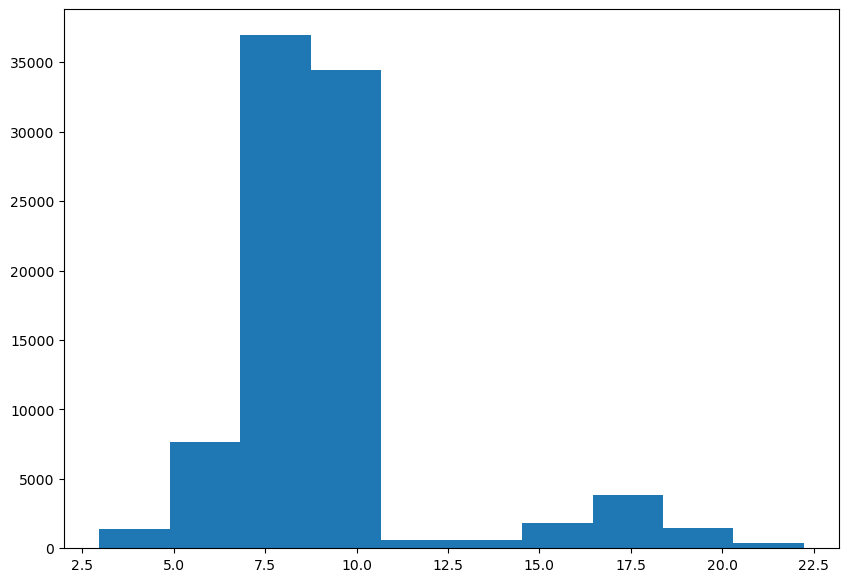

In [86]:
plt.hist(merged_lcs_gaia[merged_lcs_gaia['real_band_mag']!='--']['real_band_mag'].astype(float))

In [76]:
np.max(nona.astype(float))

21.201935

In [128]:
merged_lcs_gaia[~merged_lcs_gaia['lc_filename'].isna()]

,0,1,filename,rf,fname_star,lc_filename,Band,ztf_g_gaia_bp_rp_mag,ztf_ri_gaia_rp_mag,Diff,star_ra,star_dec,gaia_source_id
0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.2234773710177,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,i,9.892937,8.103253,2.000000,297.741068,33.901162,2.035358e+18
7,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,271.3384353885403,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,0,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,i,10.36439,9.064369,0.000000,303.563693,24.070624,1.830660e+18
8,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,544.3215794649991,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,g,9.5476885,9.562017,0.200000,295.050779,33.595638,2.046972e+18
10,lightcurve_ztf_20221020157697_000640_zi_c09_x_...,431.25131413843724,lightcurve_ztf_20221020157697_000640_zi_c09_x_...,0,lightcurve_ztf_20221020157697_000640_zi_c09_x_...,lightcurve_ztf_20221020157697_000640_zi_c09_x_...,i,11.920395,8.964765,2.000000,303.465643,26.349819,1.835710e+18
14,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,199.4156692158092,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,0,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,g,10.451465,9.646634,0.937500,298.156114,26.626200,2.027101e+18
...,...,...,...,...,...,...,...,...,...,...,...,...,...
411497,lightcurve_ztf_20221020148032_000686_zg_c09_x_...,384.52126348916585,lightcurve_ztf_20221020148032_000686_zg_c09_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c09_x_...,lightcurve_ztf_20221020148032_000686_zg_c09_x_...,g,9.658815,9.02202,0.181818,301.518460,34.828828,2.058612e+18
411498,lightcurve_ztf_20221020294271_000449_zr_c15_x_...,1889.5317563936308,lightcurve_ztf_20221020294271_000449_zr_c15_x_...,0,lightcurve_ztf_20221020294271_000449_zr_c15_x_...,lightcurve_ztf_20221020294271_000449_zr_c15_x_...,r,NaN,NaN,1.333333,18.442889,6.886937,NaN
411510,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1057.229435809247,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,r,9.413662,7.9841857,0.352941,16.933569,1.414049,2.538208e+18
411511,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,2374.9911632983717,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,0,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,i,7.136266,6.9747086,0.166667,302.616816,25.048893,1.833990e+18


In [119]:
test = classify_gaia_sources(merged_lcs_gaia[~merged_lcs_gaia['lc_filename'].isna()][:10], source_id_col='gaia_source_id', chunk_size=5000)

INFO: Query finished. [astroquery.utils.tap.core]
Classified 10/10 sources


In [120]:
test

,0,1,filename,rf,fname_star,lc_filename,gaia_source_id,source_id,in_galaxy_candidates,in_qso_candidates,...,pmdec,pmdec_error,classprob_star,classprob_galaxy,classprob_quasar,classprob_white_dwarf,classlabel_dsc,parallax_over_error,pm_over_error,likely_star_astrometric
0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.2234773710177,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,2.035358e+18,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,271.3384353885403,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,0,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,1.830660e+18,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,544.3215794649991,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,2.046972e+18,2.046972e+18,False,False,...,-0.785150,0.019760,0.999798,5.199563e-13,1.040964e-13,7.154137e-08,star,45.817834,54.086914,True
3,lightcurve_ztf_20221020157697_000640_zi_c09_x_...,431.25131413843724,lightcurve_ztf_20221020157697_000640_zi_c09_x_...,0,lightcurve_ztf_20221020157697_000640_zi_c09_x_...,lightcurve_ztf_20221020157697_000640_zi_c09_x_...,1.835710e+18,1.835710e+18,False,False,...,-0.185857,0.019149,0.999993,5.099514e-13,1.020934e-13,2.003968e-12,star,20.051504,304.837004,True
4,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,199.4156692158092,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,0,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,lightcurve_ztf_20221020163819_000640_zg_c12_x_...,2.027101e+18,2.027101e+18,False,False,...,6.629175,0.014922,0.999245,5.476924e-13,1.096492e-13,2.152279e-12,star,417.661825,805.608253,True
5,lightcurve_ztf_20221020154120_000640_zi_c11_x_...,3280.3538131119367,lightcurve_ztf_20221020154120_000640_zi_c11_x_...,0,lightcurve_ztf_20221020154120_000640_zi_c11_x_...,lightcurve_ztf_20221020154120_000640_zi_c11_x_...,1.835176e+18,1.835176e+18,False,False,...,7.767119,0.018689,0.999617,5.289273e-13,1.058924e-13,2.078538e-12,star,66.207918,467.518437,True
6,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,1447.7198538643972,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,lightcurve_ztf_20221020148032_000686_zg_c05_x_...,2.058171e+18,2.058171e+18,False,False,...,-4.631069,0.017410,0.999981,5.105532e-13,1.022139e-13,5.982764e-10,star,71.544066,285.085787,True
7,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,266.43894119262694,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,0,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,1.830529e+18,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,lightcurve_ztf_20221020141806_000686_zi_c13_x_...,1457.916814670315,lightcurve_ztf_20221020141806_000686_zi_c13_x_...,0,lightcurve_ztf_20221020141806_000686_zi_c13_x_...,lightcurve_ztf_20221020141806_000686_zi_c13_x_...,2.058950e+18,2.058950e+18,False,False,...,-3.742490,0.019624,0.999997,5.097421e-13,1.020515e-13,2.003145e-12,star,28.194192,197.460918,True
9,lightcurve_ztf_20221020141806_000686_zi_c08_x_...,388.8919747488839,lightcurve_ztf_20221020141806_000686_zi_c08_x_...,0,lightcurve_ztf_20221020141806_000686_zi_c08_x_...,lightcurve_ztf_20221020141806_000686_zi_c08_x_...,2.033219e+18,2.033219e+18,False,False,...,-3.575551,0.029886,0.999987,5.102476e-13,1.021520e-13,2.005118e-12,star,12.736608,136.948708,True


In [115]:
import numpy as np
import pandas as pd
from astroquery.gaia import Gaia



In [118]:

def classify_gaia_sources(df, source_id_col='gaia_source_id', chunk_size=5000):
    """
    Classify already-matched Gaia DR3 sources as star / galaxy / quasar / white
    dwarf, using the Discrete Source Classifier (DSC) results in
    gaiadr3.astrophysical_parameters, plus the boolean crossmatch flags in
    gaia_source as a cheap cross-check / fallback.
 
    This assumes you've already run something like query_gaia_for_stars() and
    have a 'gaia_source_id' column in df.
 
    Parameters
    ----------
    df : pd.DataFrame
        Must contain a column of Gaia DR3 source_id values.
    source_id_col : str
        Name of the column holding the source_id.
    chunk_size : int
        Number of source_ids per batch query. ADQL IN(...) clauses get slow /
        hit length limits above a few thousand ids, so we chunk.
 
    Returns
    -------
    pd.DataFrame
        df with new columns:
            classlabel_dsc          - 'star' / 'galaxy' / 'quasar' / 'white_dwarf' / NaN
            classprob_star
            classprob_galaxy
            classprob_quasar
            classprob_white_dwarf
            in_galaxy_candidates    - bool crossmatch flag from gaia_source
            in_qso_candidates       - bool crossmatch flag from gaia_source
            parallax_over_error     - astrometric fallback signal
            pm_over_error           - astrometric fallback signal (combined pmra/pmdec)
            likely_star_astrometric - True if parallax or pm is significant (>3 sigma)
    """
    out = df.copy()
    ids = out[source_id_col].dropna().astype('int64').unique().tolist()
 
    if len(ids) == 0:
        print("No valid gaia_source_id values found, nothing to classify.")
        return out
 
    results = []
    for i in range(0, len(ids), chunk_size):
        chunk = ids[i:i + chunk_size]
        id_list = ",".join(str(s) for s in chunk)
 
        query = f"""
        SELECT
            g.source_id,
            g.in_galaxy_candidates,
            g.in_qso_candidates,
            g.parallax,
            g.parallax_error,
            g.pmra,
            g.pmra_error,
            g.pmdec,
            g.pmdec_error,
            ap.classprob_dsc_combmod_star,
            ap.classprob_dsc_combmod_galaxy,
            ap.classprob_dsc_combmod_quasar,
            ap.classprob_dsc_combmod_whitedwarf
        FROM gaiadr3.gaia_source AS g
        LEFT JOIN gaiadr3.astrophysical_parameters AS ap
            ON g.source_id = ap.source_id
        WHERE g.source_id IN ({id_list})
        """
        job = Gaia.launch_job_async(query)
        res = job.get_results().to_pandas()
        results.append(res)
        print(f"Classified {min(i + chunk_size, len(ids))}/{len(ids)} sources")
 
    class_df = pd.concat(results, ignore_index=True)
    class_df = class_df.rename(columns={
        'classprob_dsc_combmod_star': 'classprob_star',
        'classprob_dsc_combmod_galaxy': 'classprob_galaxy',
        'classprob_dsc_combmod_quasar': 'classprob_quasar',
        'classprob_dsc_combmod_whitedwarf': 'classprob_white_dwarf',
    })
 
    # astrophysical_parameters doesn't provide a ready-made "best label" column
    # (that only exists in the separate qso_candidates/galaxy_candidates
    # tables), so derive it ourselves: whichever of the 4 DSC-Combmod classes
    # has the highest probability, provided that probability exceeds 0.5
    # (Gaia's own convention for classlabel_dsc). Rows with no DSC coverage
    # (all four probabilities NaN) get classlabel_dsc = None.
    prob_cols = ['classprob_star', 'classprob_galaxy', 'classprob_quasar', 'classprob_white_dwarf']
    label_map = {
        'classprob_star': 'star',
        'classprob_galaxy': 'galaxy',
        'classprob_quasar': 'quasar',
        'classprob_white_dwarf': 'white_dwarf',
    }
    probs = class_df[prob_cols]
    has_any = probs.notna().any(axis=1)
    best_col = probs.idxmax(axis=1)
    best_val = probs.max(axis=1)
    class_df['classlabel_dsc'] = np.where(
        has_any & (best_val > 0.5), best_col.map(label_map), None
    )
 
    # Astrometric fallback signal, for sources DSC doesn't cover (typically
    # faint sources without processed BP/RP spectra).
    class_df['parallax_over_error'] = (
        class_df['parallax'] / class_df['parallax_error']
    )
    pm_snr = np.sqrt(
        (class_df['pmra'] / class_df['pmra_error']) ** 2
        + (class_df['pmdec'] / class_df['pmdec_error']) ** 2
    )
    class_df['pm_over_error'] = pm_snr
    class_df['likely_star_astrometric'] = (
        (class_df['parallax_over_error'].abs() > 3) | (class_df['pm_over_error'] > 3)
    )
 
    out = out.merge(
        class_df,
        left_on=source_id_col,
        right_on='source_id',
        how='left',
        suffixes=('', '_dsc'),
    )
    return out
 
 
if __name__ == "__main__":
    # Example usage:
    # df = pd.read_csv("your_matched_sources.csv")
    # classified = classify_gaia_sources(df)
    # classified.to_csv("classified_sources.csv", index=False)
    pass
 


In [154]:
df2 = pd.read_csv('/lustre/lrspec/ZTF_data/final_df_august')

In [155]:
df2 = classify_gaia_sources(df2, source_id_col='gaia_source_id', chunk_size=5000)

INFO: Query finished. [astroquery.utils.tap.core]
Classified 87/87 sources


In [156]:
np.unique(df2['classlabel_dsc'].values.astype(str), return_counts=True)

(array(['None', 'nan', 'star', 'white_dwarf'], dtype='<U11'),
 array([ 1, 66, 32,  1]))

In [157]:
df2[df2['classlabel_dsc']=='white_dwarf']

,Unnamed: 0.13,Unnamed: 0.12,Unnamed: 0.11,Unnamed: 0.10,Unnamed: 0.9,Unnamed: 0.8,Unnamed: 0.7,Unnamed: 0.6,Unnamed: 0.5,Unnamed: 0.4,...,pmdec,pmdec_error,classprob_star,classprob_galaxy,classprob_quasar,classprob_white_dwarf,classlabel_dsc,parallax_over_error,pm_over_error,likely_star_astrometric
58,58,58,314522,314522,314522,314522,314522,314522,314522,314522,...,-3.138482,0.015042,0.000088,4.459557e-09,0.040398,0.959513,white_dwarf,37.930365,221.412399,True


In [131]:
df = pd.read_csv('/lustre/lrspec/ZTF_data/gaia_class_initial')

In [150]:
np.unique(df['classlabel_dsc'].values.astype(str), return_counts=True)

(array(['nan', 'quasar', 'star', 'white_dwarf'], dtype='<U11'),
 array([61726,    19, 28518,   412]))

In [152]:
df[df['classlabel_dsc']=='white_dwarf']

,Unnamed: 0.1,Unnamed: 0,0,1,filename,rf,fname_star,lc_filename,Band,ztf_g_gaia_bp_rp_mag,...,pmdec,pmdec_error,classprob_star,classprob_galaxy,classprob_quasar,classprob_white_dwarf,classlabel_dsc,parallax_over_error,pm_over_error,likely_star_astrometric
56,56,199,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,39324.762253,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,0,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,g,4.951148,...,0.316026,0.108456,0.000050,2.544580e-09,5.094306e-10,0.999950,white_dwarf,47.673658,159.436404,True
936,936,4174,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,2398.527804,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,g,8.721859,...,-6.927773,0.018842,0.000050,2.544580e-09,5.094306e-10,0.999950,white_dwarf,33.640601,453.717008,True
1042,1042,4675,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,2180.332050,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,g,7.8439336,...,-5.693448,0.028141,0.000082,4.191678e-09,3.474714e-02,0.965170,white_dwarf,21.992826,241.358690,True
1063,1063,4776,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,761.178570,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,g,9.068282,...,-3.138482,0.015042,0.000088,4.459557e-09,4.039832e-02,0.959513,white_dwarf,37.930365,221.412399,True
1471,1471,6577,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,752.002805,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,g,9.068282,...,-3.138482,0.015042,0.000088,4.459557e-09,4.039832e-02,0.959513,white_dwarf,37.930365,221.412399,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90228,90228,409438,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,2386.602826,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,g,8.721859,...,-6.927773,0.018842,0.000050,2.544580e-09,5.094306e-10,0.999950,white_dwarf,33.640601,453.717008,True
90266,90266,409601,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,751.440032,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,g,9.068282,...,-3.138482,0.015042,0.000088,4.459557e-09,4.039832e-02,0.959513,white_dwarf,37.930365,221.412399,True
90295,90295,409717,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,2159.707101,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,g,7.8439336,...,-5.693448,0.028141,0.000082,4.191678e-09,3.474714e-02,0.965170,white_dwarf,21.992826,241.358690,True
90390,90390,410198,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,2547.678744,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,g,7.7761617,...,-6.637562,0.019265,0.000053,2.699205e-09,3.261973e-03,0.996684,white_dwarf,29.193434,390.128936,True


In [134]:
df[df['classprob_star']<.9]

,Unnamed: 0.1,Unnamed: 0,0,1,filename,rf,fname_star,lc_filename,Band,ztf_g_gaia_bp_rp_mag,...,pmdec,pmdec_error,classprob_star,classprob_galaxy,classprob_quasar,classprob_white_dwarf,classlabel_dsc,parallax_over_error,pm_over_error,likely_star_astrometric
56,56,199,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,39324.762253,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,0,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,g,4.951148,...,0.316026,0.108456,0.000050,2.544580e-09,5.094306e-10,9.999496e-01,white_dwarf,47.673658,159.436404,True
65,65,224,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,737.736255,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,0,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,i,8.695257,...,-30.198508,0.024235,0.000001,5.096103e-11,1.020251e-11,2.002628e-10,NaN,313.027100,1989.416528,True
80,80,281,lightcurve_ztf_20221020163819_000640_zg_c07_x_...,893.805647,lightcurve_ztf_20221020163819_000640_zg_c07_x_...,0,lightcurve_ztf_20221020163819_000640_zg_c07_x_...,lightcurve_ztf_20221020163819_000640_zg_c07_x_...,g,8.929058,...,-6.759402,0.194516,0.000001,5.097249e-11,1.020480e-11,4.590426e-06,NaN,12.244367,67.834385,True
178,178,720,lightcurve_ztf_20221020294271_000449_zr_c13_x_...,733.636114,lightcurve_ztf_20221020294271_000449_zr_c13_x_...,0,lightcurve_ztf_20221020294271_000449_zr_c13_x_...,lightcurve_ztf_20221020294271_000449_zr_c13_x_...,r,9.267627,...,-35.871479,0.012036,0.000001,5.096103e-11,1.020251e-11,2.002628e-10,NaN,484.113163,3150.858706,True
194,194,787,lightcurve_ztf_20221020163819_000640_zg_c16_x_...,3526.531914,lightcurve_ztf_20221020163819_000640_zg_c16_x_...,0,lightcurve_ztf_20221020163819_000640_zg_c16_x_...,lightcurve_ztf_20221020163819_000640_zg_c16_x_...,g,7.451757,...,-3.399858,0.022845,0.000001,5.098030e-11,1.020637e-11,7.729017e-06,NaN,272.586309,176.238271,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
90410,90410,410276,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,367.494979,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,0,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,lightcurve_ztf_20221020141806_000686_zi_c16_x_...,i,9.121516,...,16.640500,0.016568,0.000001,5.096103e-11,1.020251e-11,2.002628e-10,NaN,288.452692,1710.936474,True
90439,90439,410420,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,672.228383,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,g,9.1222925,...,-27.862122,0.013059,0.000001,5.096481e-11,1.020327e-11,1.514902e-06,NaN,316.294764,2239.370009,True
90525,90525,410785,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,39902.070302,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,0,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,lightcurve_ztf_20221020163819_000640_zg_c02_x_...,g,4.951148,...,0.316026,0.108456,0.000050,2.544580e-09,5.094306e-10,9.999496e-01,white_dwarf,47.673658,159.436404,True
90527,90527,410794,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,735.708065,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,0,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,i,8.695257,...,-30.198508,0.024235,0.000001,5.096103e-11,1.020251e-11,2.002628e-10,NaN,313.027100,1989.416528,True


In [164]:
import review_findings_functions as rff

ERROR! Session/line number was not unique in database. History logging moved to new session 1603


In [6]:
def make_fname_original(df_row):
    return df_row['0'][11:50]+'.'

In [8]:
lcs_no_rf_no_29['filename'] = lcs_no_rf_no_29.apply(make_fname_original, axis=1)

In [10]:
def make_quad_original(df_row):
    return df_row['0'][51]

In [11]:
lcs_no_rf_no_29['quadrant'] = lcs_no_rf_no_29.apply(make_quad_original, axis=1)

In [12]:
lcs_no_rf_no_29['quad']=lcs_no_rf_no_29['quadrant']

In [ ]:
def make_fname_original(df_row):
    return df_row[0][11:50]+'.'

In [28]:
def make_closest_x(df_row):
    return int(df_row['0'][53:57])

def make_closest_y(df_row):
    return int(df_row['0'][58:62])

In [29]:
lcs_no_rf_no_29['closest_x'] = lcs_no_rf_no_29.apply(make_closest_x, axis=1)

In [30]:
lcs_no_rf_no_29['closest_y'] = lcs_no_rf_no_29.apply(make_closest_y, axis=1)

In [18]:
lcs_no_rf_no_29 = rff.add_band(lcs_no_rf_no_29)

In [31]:
lcs_no_rf_no_29

,Unnamed: 0,0,1,filename,rf,fname_star,quadrant,quad,closest_x,closest_y,Band
0,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.223477,ztf_20221020138241_000686_zi_c11_x_0023.,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,4,4,1499,1443,i
1,1,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,134.013313,ztf_20221020148032_000686_zg_c13_x_0017.,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,4,4,671,2743,g
2,5,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,603.206124,ztf_20221020138241_000686_zi_c16_x_0002.,0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,1,1,2185,1935,i
3,11,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,152.508538,ztf_20221020294271_000449_zr_c04_x_0011.,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1,1,897,762,r
4,13,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,946.501218,ztf_20221020138241_000686_zi_c05_x_0003.,0,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,1,1,2795,2249,i
...,...,...,...,...,...,...,...,...,...,...,...
411509,698659,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,5955.066168,ztf_20221020294271_000449_zr_c08_x_0027.,0,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,2,2,321,1017,r
411510,698661,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1057.229436,ztf_20221020294271_000449_zr_c04_x_0008.,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,4,4,1631,928,r
411511,698662,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,2374.991163,ztf_20221020154120_000640_zi_c06_x_0008.,0,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,4,4,516,439,i
411512,698663,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,164.748495,ztf_20221020148032_000686_zg_c07_x_0012.,0,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,2,2,876,1577,g


In [32]:
lcs_no_rf_no_29 = rff.add_ra_dec(lcs_no_rf_no_29)

Exception ignored in: <function FITS_rec.__del__ at 0x2b820348d760>
Traceback (most recent call last):
  File "/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/astropy/io/fits/fitsrec.py", line 626, in __del__
    def __del__(self):

KeyboardInterrupt: 


KeyboardInterrupt: 

In [33]:
test = rff.add_ra_dec(lcs_no_rf_no_29[:10])

In [40]:
"""
Batched crossmatch + classification against Gaia DR3.

Instead of looping row-by-row and hitting the Gaia archive once per source
(query_and_classify_gaia_sources), this uploads a whole chunk of coordinates
to the archive as a temporary table (tap_upload) and does ONE spatial JOIN +
window-function "best match per source" query for the entire chunk at once.
That cuts network round trips from O(n_rows) down to O(n_rows / chunk_size).

How the "best match per source" selection works without a per-row TOP 1:
  ROW_NUMBER() OVER (PARTITION BY u.upload_id ORDER BY <band-dependent mag>)
ranks all Gaia candidates within radius of each uploaded position, per
uploaded position, and we keep only rn = 1 -- i.e. the same "brightest in
BP if Band=='g' else brightest in RP" rule as before, just computed for the
whole chunk in one pass instead of one ORDER BY ... TOP 1 per row.

Usage:
    df = pd.read_csv("your_new_sources.csv")   # needs 'star_ra','star_dec','Band'
    result = query_and_classify_gaia_sources_batched(
        df, radius=9, chunk_size=2000,
        checkpoint_path="/lustre/lrspec/ZTF_data/gaia_batch_checkpoint.pkl",
    )
"""

import os
import numpy as np
import pandas as pd
from astropy.table import Table
from astroquery.gaia import Gaia


GAIA_COLUMNS = [
    'source_id', 'ra', 'dec', 'phot_g_mean_mag', 'bp_rp',
    'phot_rp_mean_mag', 'phot_bp_mean_mag', 'phot_variable_flag',
]

OUTPUT_COLUMNS = [
    'gaia_source_id',
    'ztf_g_gaia_bp_rp_mag',   # phot_bp_mean_mag (name kept from your original code)
    'ztf_ri_gaia_rp_mag',     # phot_rp_mean_mag
    'variability',
    'in_vari_summary',
    'in_galaxy_candidates',
    'in_qso_candidates',
    'classprob_star',
    'classprob_galaxy',
    'classprob_quasar',
    'classprob_white_dwarf',
    'classlabel_dsc',
]

RENAME_MAP = {
    'source_id': 'gaia_source_id',
    'phot_bp_mean_mag': 'ztf_g_gaia_bp_rp_mag',
    'phot_rp_mean_mag': 'ztf_ri_gaia_rp_mag',
    'phot_variable_flag': 'variability',
}


def _best_label(row):
    probs = {
        'star': row.get('classprob_star'),
        'galaxy': row.get('classprob_galaxy'),
        'quasar': row.get('classprob_quasar'),
        'white_dwarf': row.get('classprob_white_dwarf'),
    }
    clean = {k: v for k, v in probs.items()
             if v is not None and not (isinstance(v, float) and np.isnan(v))}
    if not clean:
        return None
    best_label = max(clean, key=clean.get)
    return best_label if clean[best_label] > 0.5 else None


def _build_batch_query(radius):
    select_cols = ', '.join(f'g.{c}' for c in GAIA_COLUMNS)
    return f"""
    SELECT * FROM (
        SELECT
            u.upload_id,
            {select_cols},
            g.in_galaxy_candidates,
            g.in_qso_candidates,
            ap.classprob_dsc_combmod_star AS classprob_star,
            ap.classprob_dsc_combmod_galaxy AS classprob_galaxy,
            ap.classprob_dsc_combmod_quasar AS classprob_quasar,
            ap.classprob_dsc_combmod_whitedwarf AS classprob_white_dwarf,
            CASE WHEN vs.source_id IS NOT NULL THEN 'True' ELSE 'False' END AS in_vari_summary,
            ROW_NUMBER() OVER (
                PARTITION BY u.upload_id
                ORDER BY CASE WHEN u.band = 'g' THEN g.phot_bp_mean_mag
                              ELSE g.phot_rp_mean_mag END ASC
            ) AS rn
        FROM tap_upload.srctable AS u
        JOIN gaiadr3.gaia_source AS g
            ON 1 = CONTAINS(POINT('ICRS', g.ra, g.dec),
                             CIRCLE('ICRS', u.ra, u.dec, {radius}/3600.0))
        LEFT JOIN gaiadr3.astrophysical_parameters AS ap
            ON g.source_id = ap.source_id
        LEFT JOIN gaiadr3.vari_summary AS vs
            ON g.source_id = vs.source_id
    ) AS ranked
    WHERE rn = 1
    """


def query_and_classify_gaia_sources_batched(olddf, radius=9, chunk_size=2000,
                                             checkpoint_path=None, resume=True):
    """
    Batched version of the crossmatch + classification pipeline: one Gaia
    archive query per chunk of rows (via a TAP table upload), instead of one
    query per row.

    Parameters
    ----------
    olddf : pd.DataFrame
        Must have 'star_ra', 'star_dec', 'Band' columns.
    radius : float
        Search radius in arcseconds.
    chunk_size : int
        Rows uploaded per query. A few thousand is usually safe. If you hit
        upload-size or timeout errors from the archive, lower this.
    checkpoint_path : str or None
        If given, results are saved here (as a pickled DataFrame) after each
        chunk, so an interrupted run can be resumed.
    resume : bool
        If True and checkpoint_path already exists, skip rows already
        present in the checkpoint.

    Returns
    -------
    pd.DataFrame
        olddf with the columns in OUTPUT_COLUMNS appended, in olddf's
        original row order.
    """
    df = olddf.copy()
    df['_upload_id'] = df.index

    valid = df[df['star_ra'].notna() & df['star_dec'].notna()]
    invalid_ids = df.index.difference(valid.index).tolist()

    all_results = []
    done_ids = set()
    if checkpoint_path is not None and resume and os.path.exists(checkpoint_path):
        prior = pd.read_pickle(checkpoint_path)
        all_results.append(prior)
        done_ids = set(prior['_upload_id'])
        print(f"Resuming: {len(done_ids)} rows already done in {checkpoint_path}")

    todo_ids = [i for i in valid.index.tolist() if i not in done_ids]

    for i in range(0, len(todo_ids), chunk_size):
        chunk_ids = todo_ids[i:i + chunk_size]
        chunk = valid.loc[chunk_ids]

        upload_table = Table({
            'upload_id': chunk['_upload_id'].astype('int64').values,
            'ra': chunk['star_ra'].astype('float64').values,
            'dec': chunk['star_dec'].astype('float64').values,
            'band': chunk['Band'].astype(str).values,
        })

        query = _build_batch_query(radius)
        print(query)
        job = Gaia.launch_job_async(
            query=query,
            upload_resource=upload_table,
            upload_table_name="srctable",
        )
        
        res = job.get_results().to_pandas()

        res = res.rename(columns=RENAME_MAP)
        res['in_vari_summary'] = res['in_vari_summary'].astype(str) == 'True'
        res['classlabel_dsc'] = res.apply(_best_label, axis=1)
        res = res.rename(columns={'upload_id': '_upload_id'})
        res = res[['_upload_id'] + OUTPUT_COLUMNS]

        matched_ids = set(res['_upload_id'])
        missing_ids = [uid for uid in chunk_ids if uid not in matched_ids]
        if missing_ids:
            missing_df = pd.DataFrame(
                {**{'_upload_id': missing_ids}, **{c: None for c in OUTPUT_COLUMNS}}
            )
            res = pd.concat([res, missing_df], ignore_index=True)

        all_results.append(res)
        print(f"Queried {min(i + chunk_size, len(todo_ids))}/{len(todo_ids)} rows "
              f"({len(missing_ids)} with no Gaia match in this chunk)")

        if checkpoint_path is not None:
            pd.concat(all_results, ignore_index=True).to_pickle(checkpoint_path)

    if invalid_ids:
        invalid_df = pd.DataFrame(
            {**{'_upload_id': invalid_ids}, **{c: None for c in OUTPUT_COLUMNS}}
        )
        all_results.append(invalid_df)

    matches = (pd.concat(all_results, ignore_index=True) if all_results
               else pd.DataFrame(columns=['_upload_id'] + OUTPUT_COLUMNS))

    df = df.merge(matches, on='_upload_id', how='left')
    df = df.set_index('_upload_id').loc[olddf.index].reset_index(drop=True)
    df.index = olddf.index
    return df


# if __name__ == "__main__":
    # Example usage:
    # df = pd.read_csv("your_new_sources.csv")
    # result = query_and_classify_gaia_sources_batched(
    #     df, radius=9, chunk_size=2000,
    #     checkpoint_path="/lustre/lrspec/ZTF_data/gaia_batch_checkpoint.pkl",
    # )
    # result.to_csv("gaia_matched_classified_batched.csv", index=False)
    # pass

In [42]:
"""
Combined pipeline: crossmatch a dataframe of positions against Gaia DR3, and
in the same query classify each match as star / galaxy / quasar / white dwarf
using the Discrete Source Classifier (DSC).

This merges the two pieces you had before:
  - query_gaia_for_stars(): per-row positional crossmatch against gaia_source,
    picking the best match by BP or RP magnitude depending on 'Band'.
  - classify_gaia_sources(): a second pass looking up DSC classification
    probabilities for each matched source_id.

Rather than doing those as two separate passes (one query per row, then a
second batch of queries after), the classification columns are now pulled
in the *same* per-row query via a LEFT JOIN, since you're already hitting
the archive once per source anyway.

Usage on new data:
    df = pd.read_csv("your_new_sources.csv")   # needs 'star_ra', 'star_dec', 'Band'
    result = query_and_classify_gaia_sources(df, radius=9,
                                              checkpoint_path="/lustre/lrspec/ZTF_data/gaia_checkpoint.npy")
"""

import numpy as np
import pandas as pd
import astropy.units as u
from astropy.coordinates import SkyCoord
from astroquery.gaia import Gaia


GAIA_COLUMNS = [
    'source_id', 'ra', 'dec', 'phot_g_mean_mag', 'bp_rp',
    'phot_rp_mean_mag', 'phot_bp_mean_mag', 'phot_variable_flag',
]

# Order matters: this must match the order values are appended in the loop
# below, and is used both for the empty/NaN row filler and the final
# DataFrame column assignment.
OUTPUT_COLUMNS = [
    'gaia_source_id',
    'ztf_g_gaia_bp_rp_mag',   # kept your original (slightly misleading) name:
                              # this is actually phot_bp_mean_mag, not bp_rp
    'ztf_ri_gaia_rp_mag',     # this is phot_rp_mean_mag
    'variability',
    'in_vari_summary',
    'in_galaxy_candidates',
    'in_qso_candidates',
    'classprob_star',
    'classprob_galaxy',
    'classprob_quasar',
    'classprob_white_dwarf',
    'classlabel_dsc',
]
EMPTY_ROW = [None] * len(OUTPUT_COLUMNS)


def _build_query(ra, dec, radius, band):
    order_col = 'phot_bp_mean_mag' if band == 'g' else 'phot_rp_mean_mag'
    select_cols = ', '.join(f'g.{c}' for c in GAIA_COLUMNS)
    return f"""
    SELECT TOP 1 {select_cols},
        g.in_galaxy_candidates,
        g.in_qso_candidates,
        ap.classprob_dsc_combmod_star AS classprob_star,
        ap.classprob_dsc_combmod_galaxy AS classprob_galaxy,
        ap.classprob_dsc_combmod_quasar AS classprob_quasar,
        ap.classprob_dsc_combmod_whitedwarf AS classprob_white_dwarf,
        CASE WHEN vs.source_id IS NOT NULL THEN 'True' ELSE 'False' END AS in_vari_summary
    FROM gaiadr3.gaia_source AS g
    LEFT JOIN gaiadr3.astrophysical_parameters AS ap
        ON g.source_id = ap.source_id
    LEFT JOIN gaiadr3.vari_summary AS vs
        ON g.source_id = vs.source_id
    WHERE CONTAINS(POINT('ICRS', g.ra, g.dec),
                   CIRCLE('ICRS', {ra}, {dec}, {radius}/3600.0)) = 1
    ORDER BY g.{order_col} ASC
    """


def _best_label(row):
    probs = {
        'star': row['classprob_star'],
        'galaxy': row['classprob_galaxy'],
        'quasar': row['classprob_quasar'],
        'white_dwarf': row['classprob_white_dwarf'],
    }
    if all(v is None or (isinstance(v, float) and np.isnan(v)) for v in probs.values()):
        return None
    best_label = max(probs, key=lambda k: (probs[k] if probs[k] is not None else -np.inf))
    best_val = probs[best_label]
    return best_label if (best_val is not None and best_val > 0.5) else None


def query_and_classify_gaia_sources(olddf, radius=9, checkpoint_path=None,
                                     checkpoint_every=1, resume_from=None):
    """
    Crossmatch each row's (star_ra, star_dec) against Gaia DR3 and classify
    the match as star/galaxy/quasar/white dwarf in the same query.

    Parameters
    ----------
    olddf : pd.DataFrame
        Must have 'star_ra', 'star_dec', and 'Band' columns.
    radius : float
        Search radius in arcseconds.
    checkpoint_path : str or None
        If given, matched rows are saved to this .npy path after every
        `checkpoint_every` rows, so a crashed/interrupted run can be resumed.
    checkpoint_every : int
        How often (in rows) to write the checkpoint file. 1 = every row
        (safest, matches your original behavior, but slower for very large runs).
    resume_from : str or None
        Path to a previously-saved checkpoint .npy to resume from. Must have
        been produced by this same function (same column layout).

    Returns
    -------
    pd.DataFrame
        olddf with the columns in OUTPUT_COLUMNS appended.
    """
    df = olddf.copy()

    new_data = []
    starting_row = 0
    if resume_from is not None:
        new_data = list(np.load(resume_from, allow_pickle=True))
        starting_row = len(new_data)
        print(f"Resuming from row {starting_row} ({resume_from})")

    for idx, row in df.iloc[starting_row:].iterrows():
        if pd.isna(row['star_ra']) or pd.isna(row['star_dec']):
            print(f"Row {idx}: NaN coordinate, skipping Gaia query.")
            new_data.append(EMPTY_ROW)
        else:
            # SkyCoord isn't strictly needed for the ADQL query itself (we pass
            # raw ra/dec straight into CIRCLE), but kept in case you want to
            # do offline separation checks later.
            _ = SkyCoord(ra=row['star_ra'] * u.deg, dec=row['star_dec'] * u.deg, frame='icrs')

            query = _build_query(row['star_ra'], row['star_dec'], radius, row['Band'])
            job = Gaia.launch_job(query)
            results = job.get_results()

            if len(results) > 0:
                best_match = results[0]
                source_id = best_match['source_id']
                is_variable = str(best_match['in_vari_summary']) == 'True'

                row_out = {
                    'gaia_source_id': source_id,
                    'ztf_g_gaia_bp_rp_mag': best_match['phot_bp_mean_mag'],
                    'ztf_ri_gaia_rp_mag': best_match['phot_rp_mean_mag'],
                    'variability': best_match['phot_variable_flag'],
                    'in_vari_summary': is_variable,
                    'in_galaxy_candidates': best_match['in_galaxy_candidates'],
                    'in_qso_candidates': best_match['in_qso_candidates'],
                    'classprob_star': best_match['classprob_star'],
                    'classprob_galaxy': best_match['classprob_galaxy'],
                    'classprob_quasar': best_match['classprob_quasar'],
                    'classprob_white_dwarf': best_match['classprob_white_dwarf'],
                }
                row_out['classlabel_dsc'] = _best_label(row_out)
                new_data.append([row_out[c] for c in OUTPUT_COLUMNS])
            else:
                new_data.append(EMPTY_ROW)

        if checkpoint_path is not None and (len(new_data) % checkpoint_every == 0):
            np.save(checkpoint_path, new_data)

    if checkpoint_path is not None:
        np.save(checkpoint_path, new_data)

    df[OUTPUT_COLUMNS] = new_data
    return df


if __name__ == "__main__":
    # Example usage:
    # df = pd.read_csv("your_new_sources.csv")
    # result = query_and_classify_gaia_sources(
    #     df, radius=9,
    #     checkpoint_path="/lustre/lrspec/ZTF_data/gaia_checkpoint_new.npy",
    # )
    # result.to_csv("gaia_matched_classified.csv", index=False)
    pass

In [43]:
query_and_classify_gaia_sources(df)

HTTPError: Error 400: 
Cannot parse query '
    SELECT TOP 1 g.source_id, g.ra, g.dec, g.phot_g_mean_mag, g.bp_rp, g.phot_rp_mean_mag, g.phot_bp_mean_mag, g.phot_variable_flag,
        g.in_galaxy_candidates,
        g.in_qso_candidates,
        ap.classprob_dsc_combmod_star AS classprob_star,
        ap.classprob_dsc_combmod_galaxy AS classprob_galaxy,
        ap.classprob_dsc_combmod_quasar AS classprob_quasar,
        ap.classprob_dsc_combmod_whitedwarf AS classprob_white_dwarf,
        CASE WHEN vs.source_id IS NOT NULL THEN 'True' ELSE 'False' END AS in_vari_summary
    FROM gaiadr3.gaia_source AS g
    LEFT JOIN gaiadr3.astrophysical_parameters AS ap
        ON g.source_id = ap.source_id
    LEFT JOIN gaiadr3.vari_summary AS vs
        ON g.source_id = vs.source_id
    WHERE CONTAINS(POINT('ICRS', g.ra, g.dec),
                   CIRCLE('ICRS', 297.741067801113, 33.90116239259298, 9/3600.0)) = 1
    ORDER BY g.phot_rp_mean_mag ASC
    ' for job 'd2c12ed8-a2ff-11f1-a16e-bc97e148b7

In [46]:
def query_and_classify_gaia_sources_batched(
    olddf,
    radius=9,
    chunk_size=2000,
    checkpoint_path=None,
    resume=True,
    classification_id_chunk=500,
):
    """
    Batched Gaia DR3 crossmatch + classification.

    Pipeline
    --------
    1. Upload input coordinates to Gaia.
    2. Spatially crossmatch against gaiadr3.gaia_source only.
    3. Select the best Gaia match locally in pandas:
         - Band == 'g'  -> smallest phot_bp_mean_mag
         - otherwise    -> smallest phot_rp_mean_mag
    4. Query astrophysical_parameters for the selected source_ids.
    5. Query vari_summary separately for the selected source_ids.
    6. Merge everything locally.
    7. Save checkpoint after every input chunk.

    The output columns are exactly OUTPUT_COLUMNS.
    Original row order and original DataFrame index are preserved.
    """

    # ==============================================================
    # Validation
    # ==============================================================

    required_columns = {"star_ra", "star_dec", "Band"}
    missing = required_columns - set(olddf.columns)

    if missing:
        raise ValueError(
            f"Input DataFrame is missing required columns: "
            f"{sorted(missing)}"
        )

    if radius <= 0:
        raise ValueError("radius must be > 0")

    if chunk_size <= 0:
        raise ValueError("chunk_size must be > 0")

    if classification_id_chunk <= 0:
        raise ValueError("classification_id_chunk must be > 0")

    # ==============================================================
    # Preserve original index and create guaranteed unique ID
    # ==============================================================

    original_index = olddf.index.copy()

    df = olddf.copy()

    df["_upload_id"] = np.arange(
        len(df),
        dtype=np.int64,
    )

    # ==============================================================
    # Helper: empty result
    # ==============================================================

    def _empty_result(upload_ids):

        return pd.DataFrame(
            {
                "_upload_id": np.asarray(
                    upload_ids,
                    dtype=np.int64,
                ),
                **{
                    col: [None] * len(upload_ids)
                    for col in OUTPUT_COLUMNS
                },
            }
        )

    # ==============================================================
    # Helper: make ADQL IN clause
    # ==============================================================

    def _source_id_in_clause(source_ids):

        source_ids = np.asarray(
            source_ids,
            dtype=np.int64,
        )

        return ", ".join(
            str(int(x))
            for x in source_ids
        )

    # ==============================================================
    # Helper: query astrophysical_parameters
    # ==============================================================

    def _query_astrophysical_parameters(source_ids):

        source_ids = np.asarray(
            source_ids,
            dtype=np.int64,
        )

        if len(source_ids) == 0:
            return pd.DataFrame(
                columns=[
                    "gaia_source_id",
                    "classprob_star",
                    "classprob_galaxy",
                    "classprob_quasar",
                    "classprob_white_dwarf",
                ]
            )

        pieces = []

        for j in range(
            0,
            len(source_ids),
            classification_id_chunk,
        ):

            ids = source_ids[
                j:j + classification_id_chunk
            ]

            id_list = _source_id_in_clause(ids)

            query = f"""
            SELECT
                source_id,
                classprob_dsc_combmod_star
                    AS classprob_star,
                classprob_dsc_combmod_galaxy
                    AS classprob_galaxy,
                classprob_dsc_combmod_quasar
                    AS classprob_quasar,
                classprob_dsc_combmod_whitedwarf
                    AS classprob_white_dwarf
            FROM gaiadr3.astrophysical_parameters
            WHERE source_id IN ({id_list})
            """

            print(
                f"    astrophysical_parameters: "
                f"{j + 1}-{min(j + classification_id_chunk, len(source_ids))}"
                f"/{len(source_ids)}"
            )

            job = Gaia.launch_job_async(
                query=query
            )

            piece = job.get_results().to_pandas()

            if not piece.empty:
                pieces.append(piece)

        if not pieces:
            return pd.DataFrame(
                columns=[
                    "gaia_source_id",
                    "classprob_star",
                    "classprob_galaxy",
                    "classprob_quasar",
                    "classprob_white_dwarf",
                ]
            )

        result = pd.concat(
            pieces,
            ignore_index=True,
        )

        result = result.rename(
            columns={
                "source_id": "gaia_source_id",
            }
        )

        return result[
            [
                "gaia_source_id",
                "classprob_star",
                "classprob_galaxy",
                "classprob_quasar",
                "classprob_white_dwarf",
            ]
        ]

    # ==============================================================
    # Helper: query vari_summary separately
    # ==============================================================

    def _query_vari_summary(source_ids):

        source_ids = np.asarray(
            source_ids,
            dtype=np.int64,
        )

        if len(source_ids) == 0:
            return pd.DataFrame(
                columns=[
                    "gaia_source_id",
                    "in_vari_summary",
                ]
            )

        pieces = []

        for j in range(
            0,
            len(source_ids),
            classification_id_chunk,
        ):

            ids = source_ids[
                j:j + classification_id_chunk
            ]

            id_list = _source_id_in_clause(ids)

            query = f"""
            SELECT DISTINCT
                source_id
            FROM gaiadr3.vari_summary
            WHERE source_id IN ({id_list})
            """

            print(
                f"    vari_summary: "
                f"{j + 1}-{min(j + classification_id_chunk, len(source_ids))}"
                f"/{len(source_ids)}"
            )

            job = Gaia.launch_job_async(
                query=query
            )

            piece = job.get_results().to_pandas()

            if not piece.empty:
                pieces.append(piece)

        # No sources in vari_summary.
        if not pieces:

            return pd.DataFrame(
                {
                    "gaia_source_id": source_ids,
                    "in_vari_summary": False,
                }
            )

        found = pd.concat(
            pieces,
            ignore_index=True,
        )

        found = found.rename(
            columns={
                "source_id": "gaia_source_id",
            }
        )

        found_ids = set(
            found["gaia_source_id"]
            .astype(np.int64)
        )

        return pd.DataFrame(
            {
                "gaia_source_id": source_ids,
                "in_vari_summary": [
                    int(x) in found_ids
                    for x in source_ids
                ],
            }
        )

    # ==============================================================
    # 1. Load checkpoint
    # ==============================================================

    all_results = []
    done_ids = set()

    if (
        checkpoint_path is not None
        and resume
        and os.path.exists(checkpoint_path)
    ):

        print(
            f"Loading checkpoint: {checkpoint_path}"
        )

        prior = pd.read_pickle(
            checkpoint_path
        )

        expected = {
            "_upload_id",
            *OUTPUT_COLUMNS,
        }

        missing_checkpoint = (
            expected - set(prior.columns)
        )

        if missing_checkpoint:
            raise ValueError(
                "Checkpoint is missing columns: "
                f"{sorted(missing_checkpoint)}"
            )

        all_results.append(prior)

        done_ids = set(
            prior["_upload_id"]
            .astype(np.int64)
        )

        print(
            f"Resuming: {len(done_ids)} rows already completed."
        )

    # ==============================================================
    # 2. Valid coordinates
    # ==============================================================

    valid_mask = (
        df["star_ra"].notna()
        & df["star_dec"].notna()
    )

    valid = df.loc[
        valid_mask
    ].copy()

    invalid_ids = (
        df.loc[
            ~valid_mask,
            "_upload_id"
        ]
        .astype(np.int64)
        .tolist()
    )

    todo_ids = [
        int(x)
        for x in valid["_upload_id"]
        if int(x) not in done_ids
    ]

    print(
        f"Total input rows:       {len(df)}"
    )
    print(
        f"Rows with coordinates:  {len(valid)}"
    )
    print(
        f"Rows without coords:    {len(invalid_ids)}"
    )
    print(
        f"Rows already completed: {len(done_ids)}"
    )
    print(
        f"Rows remaining:         {len(todo_ids)}"
    )

    # ==============================================================
    # 3. Process input chunks
    # ==============================================================

    for start in range(
        0,
        len(todo_ids),
        chunk_size,
    ):

        chunk_ids = todo_ids[
            start:start + chunk_size
        ]

        chunk = valid[
            valid["_upload_id"].isin(chunk_ids)
        ].copy()

        print()
        print("=" * 70)
        print(
            f"Processing rows "
            f"{start + 1}-"
            f"{min(start + len(chunk), len(todo_ids))} "
            f"of {len(todo_ids)}"
        )

        # ==========================================================
        # STAGE 1
        # Spatial crossmatch
        # ==========================================================

        upload_table = Table(
            {
                "upload_id":
                    chunk["_upload_id"]
                    .astype("int64")
                    .to_numpy(),

                "ra":
                    chunk["star_ra"]
                    .astype("float64")
                    .to_numpy(),

                "dec":
                    chunk["star_dec"]
                    .astype("float64")
                    .to_numpy(),

                "band":
                    chunk["Band"]
                    .astype(str)
                    .to_numpy(),
            }
        )

        spatial_query = f"""
        SELECT
            u.upload_id,
            u.band,

            g.source_id,
            g.ra,
            g.dec,

            g.phot_g_mean_mag,
            g.bp_rp,
            g.phot_rp_mean_mag,
            g.phot_bp_mean_mag,
            g.phot_variable_flag,

            g.in_galaxy_candidates,
            g.in_qso_candidates

        FROM tap_upload.srctable AS u

        JOIN gaiadr3.gaia_source AS g
            ON 1 = CONTAINS(
                POINT('ICRS', g.ra, g.dec),
                CIRCLE(
                    'ICRS',
                    u.ra,
                    u.dec,
                    {float(radius)}/3600.0
                )
            )
        """

        print(
            "Stage 1: spatial crossmatch..."
        )

        job = Gaia.launch_job_async(
            query=spatial_query,
            upload_resource=upload_table,
            upload_table_name="srctable",
        )

        candidates = (
            job.get_results()
            .to_pandas()
        )

        print(
            f"  Gaia returned "
            f"{len(candidates)} candidate matches."
        )

        # ==========================================================
        # No Gaia candidates
        # ==========================================================

        if candidates.empty:

            print(
                "  No Gaia matches for this chunk."
            )

            res = _empty_result(
                chunk_ids
            )

            all_results.append(
                res
            )

            if checkpoint_path is not None:

                checkpoint = (
                    pd.concat(
                        all_results,
                        ignore_index=True,
                    )
                    .sort_values("_upload_id")
                    .drop_duplicates(
                        "_upload_id",
                        keep="last",
                    )
                )

                checkpoint.to_pickle(
                    checkpoint_path
                )

            continue

        # ==========================================================
        # Normalize column names
        # ==========================================================

        candidates.columns = [
            str(c).lower()
            for c in candidates.columns
        ]

        # ==========================================================
        # STAGE 2
        # Select best Gaia match locally
        # ==========================================================

        print(
            "Stage 2: selecting best Gaia match locally..."
        )

        candidates[
            "phot_bp_mean_mag"
        ] = pd.to_numeric(
            candidates[
                "phot_bp_mean_mag"
            ],
            errors="coerce",
        )

        candidates[
            "phot_rp_mean_mag"
        ] = pd.to_numeric(
            candidates[
                "phot_rp_mean_mag"
            ],
            errors="coerce",
        )

        candidates[
            "match_mag"
        ] = np.where(
            candidates["band"]
            .astype(str)
            .str.lower()
            .eq("g"),

            candidates[
                "phot_bp_mean_mag"
            ],

            candidates[
                "phot_rp_mean_mag"
            ],
        )

        # Sort by requested magnitude.
        #
        # source_id provides a deterministic tie breaker.
        candidates = candidates.sort_values(
            [
                "upload_id",
                "match_mag",
                "source_id",
            ],
            ascending=True,
            na_position="last",
        )

        best = (
            candidates
            .drop_duplicates(
                "upload_id",
                keep="first",
            )
            .copy()
        )

        best = best.rename(
            columns={
                "source_id": "gaia_source_id",
            }
        )

        print(
            f"  Selected "
            f"{len(best)} best Gaia matches."
        )

        # ==========================================================
        # STAGE 3A
        # astrophysical_parameters
        # ==========================================================

        selected_source_ids = (
            best["gaia_source_id"]
            .dropna()
            .astype(np.int64)
            .unique()
        )

        print(
            "Stage 3a: retrieving "
            "astrophysical parameters..."
        )

        astrophysical = (
            _query_astrophysical_parameters(
                selected_source_ids
            )
        )

        print(
            f"  Returned classification data "
            f"for {len(astrophysical)} sources."
        )

        # ==========================================================
        # STAGE 3B
        # vari_summary
        # ==========================================================

        print(
            "Stage 3b: retrieving variability summary..."
        )

        variability = (
            _query_vari_summary(
                selected_source_ids
            )
        )

        print(
            f"  Checked variability status "
            f"for {len(variability)} sources."
        )

        # ==========================================================
        # Merge auxiliary information locally
        # ==========================================================

        best = best.merge(
            astrophysical,
            on="gaia_source_id",
            how="left",
        )

        best = best.merge(
            variability,
            on="gaia_source_id",
            how="left",
        )

        # Any source that somehow did not appear in vari_summary
        # is explicitly False.
        best["in_vari_summary"] = (
            best["in_vari_summary"]
            .fillna(False)
            .astype(bool)
        )

        # ==========================================================
        # Construct exact output columns
        # ==========================================================

        res = pd.DataFrame(
            {
                "_upload_id":
                    best["upload_id"],

                "gaia_source_id":
                    best["gaia_source_id"],

                "ztf_g_gaia_bp_rp_mag":
                    best["phot_bp_mean_mag"],

                "ztf_ri_gaia_rp_mag":
                    best["phot_rp_mean_mag"],

                "variability":
                    best["phot_variable_flag"],

                "in_vari_summary":
                    best["in_vari_summary"],

                "in_galaxy_candidates":
                    best["in_galaxy_candidates"],

                "in_qso_candidates":
                    best["in_qso_candidates"],

                "classprob_star":
                    best["classprob_star"],

                "classprob_galaxy":
                    best["classprob_galaxy"],

                "classprob_quasar":
                    best["classprob_quasar"],

                "classprob_white_dwarf":
                    best["classprob_white_dwarf"],
            }
        )

        # ==========================================================
        # Best DSC label
        # ==========================================================

        res["classlabel_dsc"] = res.apply(
            _best_label,
            axis=1,
        )

        # Exact column order.
        res = res[
            [
                "_upload_id",
                *OUTPUT_COLUMNS,
            ]
        ]

        # ==========================================================
        # Add unmatched sources
        # ==========================================================

        matched_ids = set(
            res["_upload_id"]
            .astype(np.int64)
        )

        missing_ids = [
            int(x)
            for x in chunk_ids
            if int(x) not in matched_ids
        ]

        if missing_ids:

            print(
                f"  {len(missing_ids)} sources "
                f"had no Gaia match within {radius}\"."
            )

            res = pd.concat(
                [
                    res,
                    _empty_result(
                        missing_ids
                    ),
                ],
                ignore_index=True,
            )

        # ==========================================================
        # Store chunk
        # ==========================================================

        res = (
            res
            .sort_values("_upload_id")
            .drop_duplicates(
                "_upload_id",
                keep="last",
            )
        )

        all_results.append(
            res
        )

        # ==========================================================
        # Checkpoint
        # ==========================================================

        if checkpoint_path is not None:

            checkpoint = (
                pd.concat(
                    all_results,
                    ignore_index=True,
                )
                .sort_values("_upload_id")
                .drop_duplicates(
                    "_upload_id",
                    keep="last",
                )
            )

            checkpoint.to_pickle(
                checkpoint_path
            )

            print(
                f"  Checkpoint saved to "
                f"{checkpoint_path}"
            )

    # ==============================================================
    # 4. Invalid-coordinate rows
    # ==============================================================

    if invalid_ids:

        all_results.append(
            _empty_result(
                invalid_ids
            )
        )

    # ==============================================================
    # 5. Combine results
    # ==============================================================

    if all_results:

        matches = (
            pd.concat(
                all_results,
                ignore_index=True,
            )
            .sort_values("_upload_id")
            .drop_duplicates(
                "_upload_id",
                keep="last",
            )
        )

    else:

        matches = pd.DataFrame(
            columns=[
                "_upload_id",
                *OUTPUT_COLUMNS,
            ]
        )

    # ==============================================================
    # 6. Merge back onto original DataFrame
    # ==============================================================

    result = df.merge(
        matches,
        on="_upload_id",
        how="left",
        sort=False,
    )

    # Guaranteed original order because _upload_id
    # was generated as np.arange(len(df)).
    result = (
        result
        .sort_values("_upload_id")
        .drop(columns="_upload_id")
    )

    # Restore original index.
    result.index = original_index

    return result


In [47]:
def _best_label(row):
    probs = {
        "star": row.get("classprob_star"),
        "galaxy": row.get("classprob_galaxy"),
        "quasar": row.get("classprob_quasar"),
        "white_dwarf": row.get("classprob_white_dwarf"),
    }

    clean = {}

    for label, value in probs.items():
        if pd.notna(value):
            clean[label] = float(value)

    if not clean:
        return None

    best_label = max(clean, key=clean.get)

    return (
        best_label
        if clean[best_label] > 0.5
        else None
    )


In [48]:
df = test
result = query_and_classify_gaia_sources_batched(
    df, radius=9, chunk_size=2000,
    checkpoint_path="/lustre/lrspec/ZTF_data/gaia_batch_checkpoint.pkl",
    resume=False)


Total input rows:       10
Rows with coordinates:  10
Rows without coords:    0
Rows already completed: 0
Rows remaining:         10

Processing rows 1-10 of 10
Stage 1: spatial crossmatch...
INFO: Query finished. [astroquery.utils.tap.core]
  Gaia returned 47 candidate matches.
Stage 2: selecting best Gaia match locally...
  Selected 10 best Gaia matches.
Stage 3a: retrieving astrophysical parameters...
    astrophysical_parameters: 1-10/10
INFO: Query finished. [astroquery.utils.tap.core]
  Returned classification data for 10 sources.
Stage 3b: retrieving variability summary...
    vari_summary: 1-10/10
INFO: Query finished. [astroquery.utils.tap.core]
  Checked variability status for 10 sources.
  Checkpoint saved to /lustre/lrspec/ZTF_data/gaia_batch_checkpoint.pkl


In [49]:
result

,Unnamed: 0,0,1,filename,rf,fname_star,quadrant,quad,closest_x,closest_y,...,ztf_ri_gaia_rp_mag,variability,in_vari_summary,in_galaxy_candidates,in_qso_candidates,classprob_star,classprob_galaxy,classprob_quasar,classprob_white_dwarf,classlabel_dsc
0,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.223477,ztf_20221020138241_000686_zi_c11_x_0023.,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,4,4,1499,1443,...,8.103253,NOT_AVAILABLE,False,False,False,0.999987,5.102609e-13,1.021554e-13,2.005184e-12,star
1,1,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,134.013313,ztf_20221020148032_000686_zg_c13_x_0017.,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,4,4,671,2743,...,10.306623,VARIABLE,True,False,False,0.999024,5.588265e-13,1.118783e-13,1.533995e-09,star
2,5,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,603.206124,ztf_20221020138241_000686_zi_c16_x_0002.,0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,1,1,2185,1935,...,8.555096,NOT_AVAILABLE,False,False,False,0.999947,5.122910e-13,1.025618e-13,2.013162e-12,star
3,11,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,152.508538,ztf_20221020294271_000449_zr_c04_x_0011.,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1,1,897,762,...,10.147923,NOT_AVAILABLE,False,False,False,0.999986,5.102803e-13,1.021593e-13,3.043411e-10,star
4,13,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,946.501218,ztf_20221020138241_000686_zi_c05_x_0003.,0,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,1,1,2795,2249,...,8.025301,NOT_AVAILABLE,False,False,False,0.999621,5.288756e-13,1.058821e-13,7.022827e-08,star
5,15,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,372.029251,ztf_20221020154120_000640_zi_c06_x_0000.,0,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,1,1,556,1962,...,9.159395,NOT_AVAILABLE,False,False,False,0.998258,5.974694e-13,1.196147e-13,2.347889e-12,star
6,16,lightcurve_ztf_20221020141806_000686_zi_c10_x_...,160.866498,ztf_20221020141806_000686_zi_c10_x_0003.,0,lightcurve_ztf_20221020141806_000686_zi_c10_x_...,1,1,1235,2181,...,9.552163,NOT_AVAILABLE,False,False,False,0.992964,8.645757e-13,1.730899e-13,3.397543e-12,star
7,17,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,271.338435,ztf_20221020157697_000640_zi_c01_x_0002.,0,lightcurve_ztf_20221020157697_000640_zi_c01_x_...,2,2,918,258,...,9.064369,NOT_AVAILABLE,False,False,False,0.999948,5.122246e-13,1.025485e-13,4.044819e-10,star
8,19,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,544.321579,ztf_20221020148032_000686_zg_c12_x_0025.,0,lightcurve_ztf_20221020148032_000686_zg_c12_x_...,4,4,2864,2400,...,9.562017,NOT_AVAILABLE,False,False,False,0.999798,5.199563e-13,1.040964e-13,7.154137e-08,star
9,20,lightcurve_ztf_20221020148032_000686_zg_c10_x_...,139.757072,ztf_20221020148032_000686_zg_c10_x_0008.,0,lightcurve_ztf_20221020148032_000686_zg_c10_x_...,4,4,363,1364,...,7.983143,NOT_AVAILABLE,False,False,False,0.999972,5.110079e-13,1.023049e-13,2.008120e-12,star


In [53]:
lcs_no_rf_no_29

,Unnamed: 0,0,1,filename,rf,fname_star,quadrant,quad,closest_x,closest_y,Band
0,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,879.223477,ztf_20221020138241_000686_zi_c11_x_0023.,0,lightcurve_ztf_20221020138241_000686_zi_c11_x_...,4,4,1499,1443,i
1,1,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,134.013313,ztf_20221020148032_000686_zg_c13_x_0017.,0,lightcurve_ztf_20221020148032_000686_zg_c13_x_...,4,4,671,2743,g
2,5,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,603.206124,ztf_20221020138241_000686_zi_c16_x_0002.,0,lightcurve_ztf_20221020138241_000686_zi_c16_x_...,1,1,2185,1935,i
3,11,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,152.508538,ztf_20221020294271_000449_zr_c04_x_0011.,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1,1,897,762,r
4,13,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,946.501218,ztf_20221020138241_000686_zi_c05_x_0003.,0,lightcurve_ztf_20221020138241_000686_zi_c05_x_...,1,1,2795,2249,i
...,...,...,...,...,...,...,...,...,...,...,...
411509,698659,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,5955.066168,ztf_20221020294271_000449_zr_c08_x_0027.,0,lightcurve_ztf_20221020294271_000449_zr_c08_x_...,2,2,321,1017,r
411510,698661,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,1057.229436,ztf_20221020294271_000449_zr_c04_x_0008.,0,lightcurve_ztf_20221020294271_000449_zr_c04_x_...,4,4,1631,928,r
411511,698662,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,2374.991163,ztf_20221020154120_000640_zi_c06_x_0008.,0,lightcurve_ztf_20221020154120_000640_zi_c06_x_...,4,4,516,439,i
411512,698663,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,164.748495,ztf_20221020148032_000686_zg_c07_x_0012.,0,lightcurve_ztf_20221020148032_000686_zg_c07_x_...,2,2,876,1577,g
